In [1]:
%pip install -q numpy pandas scipy scikit-learn matplotlib seaborn geopandas pyogrio shapely joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("torch") is None:
    print("Installing CPU-compatible PyTorch...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "torch",
        "--index-url",
        "https://download.pytorch.org/whl/cpu"
    ])
else:
    print("PyTorch is already installed.")

PyTorch is already installed.


# Importing libraries and configuring the experiment

In [3]:
import os
import re
import gc
import json
import random
import warnings

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

from scipy import sparse
from scipy.spatial import cKDTree

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F

from copy import deepcopy

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")

torch.set_num_threads(4)

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
Device: cpu
GPU available: False


# Loading the dataset

In [4]:
DATA_ROOT = Path(r"C:\Users\user\Desktop\Dataset IIV\Models")

MODEL_ID = 1

if (DATA_ROOT / "Models" / "Model_1").exists():

    MODEL_DIR = DATA_ROOT / "Models" / "Model_1"

elif (DATA_ROOT / "Model_1").exists():

    MODEL_DIR = DATA_ROOT / "Model_1"

else:

    raise FileNotFoundError(
        "Could not locate Model_1. Check DATA_ROOT."
    )

TRAIN_DIR = MODEL_DIR / "train"
TEST_DIR = MODEL_DIR / "test"
SHAPE_DIR = MODEL_DIR / "shapefiles"

OUTPUT_DIR = DATA_ROOT / "Research_Results_Physics_Informed_GNN"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODEL_DIR)
print("Training directory:", TRAIN_DIR)
print("Testing directory:", TEST_DIR)
print("Shapefile directory:", SHAPE_DIR)
print("Results directory:", OUTPUT_DIR)

Model directory: C:\Users\user\Desktop\Dataset IIV\Models\Model_1
Training directory: C:\Users\user\Desktop\Dataset IIV\Models\Model_1\train
Testing directory: C:\Users\user\Desktop\Dataset IIV\Models\Model_1\test
Shapefile directory: C:\Users\user\Desktop\Dataset IIV\Models\Model_1\shapefiles
Results directory: C:\Users\user\Desktop\Dataset IIV\Models\Research_Results_Physics_Informed_GNN


# Checking the directory and rainfall events

In [5]:
train_events = sorted(
    [p for p in TRAIN_DIR.glob("event_*") if p.is_dir()],
    key=lambda p: int(p.name.split("_")[1])
)

test_events = sorted(
    [p for p in TEST_DIR.glob("event_*") if p.is_dir()],
    key=lambda p: int(p.name.split("_")[1])
)

print("Number of training events:", len(train_events))
print("Number of official test events:", len(test_events))

print("\nFirst 10 training events:")

for event in train_events[:10]:
    print(event.name)

print("\nFirst 10 official test events:")

for event in test_events[:10]:
    print(event.name)

Number of training events: 68
Number of official test events: 29

First 10 training events:
event_1
event_2
event_3
event_4
event_6
event_7
event_9
event_10
event_11
event_12

First 10 official test events:
event_5
event_8
event_18
event_22
event_26
event_29
event_31
event_33
event_35
event_37


# Inspecting the CSV files

In [6]:
static_files = [
    "1d_edge_index.csv",
    "1d_edges_static.csv",
    "1d_nodes_static.csv",
    "1d2d_connections.csv",
    "2d_edge_index.csv",
    "2d_edges_static.csv",
    "2d_nodes_static.csv"
]

dynamic_files = [
    "1d_edges_dynamic_all.csv",
    "1d_nodes_dynamic_all.csv",
    "2d_edges_dynamic_all.csv",
    "2d_nodes_dynamic_all.csv",
    "timesteps.csv"
]
print("STATIC FILES")

for file in static_files:

    path = TRAIN_DIR / file

    df = pd.read_csv(path, nrows=5)

    print("\nFile:", file)
    print("Columns:", df.columns.tolist())
    print("Sample shape:", df.shape)

    display(df.head(3))

print("\nDYNAMIC FILES")

sample_event = train_events[0]

for file in dynamic_files:

    path = sample_event / file

    df = pd.read_csv(path, nrows=5)

    print("\nFile:", file)
    print("Columns:", df.columns.tolist())
    print("Sample shape:", df.shape)

    display(df.head(3))

STATIC FILES

File: 1d_edge_index.csv
Columns: ['edge_idx', 'from_node', 'to_node']
Sample shape: (5, 3)


,edge_idx,from_node,to_node
0,0,0,16
1,1,13,12
2,2,3,13



File: 1d_edges_static.csv
Columns: ['edge_idx', 'relative_position_x', 'relative_position_y', 'length', 'diameter', 'shape', 'roughness', 'slope']
Sample shape: (5, 8)


,edge_idx,relative_position_x,relative_position_y,length,diameter,shape,roughness,slope
0,0,-99.749,-130.076,163.919586,2.50,0.0,0.02,0.035462
1,1,-26.837,-36.634,45.412273,2.00,0.0,0.02,0.023447
2,2,-11.692,5.349,12.857475,1.25,0.0,0.02,0.014789



File: 1d_nodes_static.csv
Columns: ['node_idx', 'position_x', 'position_y', 'depth', 'invert_elevation', 'surface_elevation', 'base_area']
Sample shape: (5, 7)


,node_idx,position_x,position_y,depth,invert_elevation,surface_elevation,base_area
0,0,802465.60,349898.84,8.977997,292.342,301.32,12.56
1,1,802528.94,349713.56,6.195984,295.164,301.36,12.56
2,2,802430.44,349608.60,5.480011,297.610,303.09,12.56


... (14 outputs left out)


File: 2d_nodes_dynamic_all.csv
Columns: ['timestep', 'node_idx', 'rainfall', 'water_level', 'water_volume']
Sample shape: (5, 5)


,timestep,node_idx,rainfall,water_level,water_volume
0,0,0,0.143333,329.936523,2.127534
1,0,1,0.143333,329.985474,0.835427
2,0,2,0.143333,329.880676,1.661489



File: timesteps.csv
Columns: ['timestep_idx', 'timestamp']
Sample shape: (5, 2)


,timestep_idx,timestamp
0,0,2025-10-02 04:00:00
1,1,2025-10-02 04:05:00
2,2,2025-10-02 04:10:00


# Loading and processing the static data
# Create helper functions for identifying CSV columns

In [7]:
def normalize_name(name):

    name = str(name).lower()

    name = re.sub(r"[^a-z0-9]+", "_", name)

    return name.strip("_")
def find_column(df, candidates):

    columns = {
        normalize_name(col): col
        for col in df.columns
    }

    normalized_candidates = [
        normalize_name(x)
        for x in candidates
    ]

    for candidate in normalized_candidates:

        if candidate in columns:

            return columns[candidate]

    for candidate in normalized_candidates:

        for normalized, original in columns.items():

            if candidate in normalized:

                return original

    return None

def numeric_column(df, candidates, default_value=np.nan):

    col = find_column(df, candidates)

    if col is None:

        return np.full(len(df), default_value, dtype=np.float32)

    return pd.to_numeric(
        df[col],
        errors="coerce"
    ).to_numpy(dtype=np.float32)


def entity_ids(df, n, kind):

    candidates = [
        f"{kind}_id",
        f"{kind}_idx",
        f"{kind}_index",
        "node_id",
        "node_idx",
        "node_index",
        "id",
        "index"
    ]

    col = find_column(df, candidates)

    if col is None:

        return np.arange(n)

    values = df[col].to_numpy()

    if len(values) != n:

        return np.arange(n)

    return values

def clean_array(x):

    x = np.asarray(x, dtype=np.float32)

    x[~np.isfinite(x)] = np.nan

    return x

# Loading the Static CSV files

In [8]:
static_1d_nodes = pd.read_csv(
    TRAIN_DIR / "1d_nodes_static.csv"
)

static_2d_nodes = pd.read_csv(
    TRAIN_DIR / "2d_nodes_static.csv"
)

static_1d_edges = pd.read_csv(
    TRAIN_DIR / "1d_edges_static.csv"
)

static_2d_edges = pd.read_csv(
    TRAIN_DIR / "2d_edges_static.csv"
)

connections_1d2d = pd.read_csv(
    TRAIN_DIR / "1d2d_connections.csv"
)

edge_index_1d = pd.read_csv(
    TRAIN_DIR / "1d_edge_index.csv"
)

edge_index_2d = pd.read_csv(
    TRAIN_DIR / "2d_edge_index.csv"
)
N1 = len(static_1d_nodes)
N2 = len(static_2d_nodes)
N1_EDGES = len(edge_index_1d)
N2_EDGES = len(edge_index_2d)

print("1D drainage nodes:", N1)
print("2D surface nodes:", N2)
print("1D edges:", N1_EDGES)
print("2D edges:", N2_EDGES)
print("1D to 2D connections:", len(connections_1d2d))
print("Total nodes:", N1 + N2)

1D drainage nodes: 17
2D surface nodes: 3716
1D edges: 16
2D edges: 7935
1D to 2D connections: 16
Total nodes: 3733


# Extracting the graph connections
## The graph will contain three types of connections:
## 1. Underground drainage connections.
## 2. Surface water connections.
## 3. Connections between underground drainage and surface water.

In [9]:
def load_edge_pairs(
    df,
    n_source,
    n_target,
    source_candidates=None,
    target_candidates=None
):

    if source_candidates is None:

        source_candidates = [
            "source",
            "src",
            "from_node",
            "from",
            "start_node",
            "source_index",
            "from_index",
            "node_1"
        ]

    if target_candidates is None:

        target_candidates = [
            "target",
            "dst",
            "to_node",
            "to",
            "end_node",
            "target_index",
            "to_index",
            "node_2"
        ]

    src_col = find_column(df, source_candidates)

    dst_col = find_column(df, target_candidates)

    if src_col is not None and dst_col is not None:

        pairs = df[[src_col, dst_col]].to_numpy()

    else:

        numeric = df.select_dtypes(include=np.number)

        if numeric.shape[1] < 2:

            raise ValueError(
                "Could not identify two connectivity columns."
            )

        pairs = numeric.iloc[:, :2].to_numpy()

    pairs = np.asarray(pairs, dtype=np.int64)

    if pairs.ndim != 2:

        raise ValueError("Invalid edge index shape.")

    if pairs.shape[1] != 2 and pairs.shape[0] == 2:

        pairs = pairs.T

    if pairs.shape[1] != 2:

        raise ValueError("Edge index must contain two columns.")

    if (
        pairs.min() >= 1
        and pairs.max() == n_source
        and n_source == n_target
    ):

        pairs = pairs - 1

    if pairs.min() < 0:

        raise ValueError("Negative node index detected.")

    if pairs[:, 0].max() >= n_source:

        raise ValueError("Source node index exceeds node count.")

    if pairs[:, 1].max() >= n_target:

        raise ValueError("Target node index exceeds node count.")

    return pairs
pairs_1d = load_edge_pairs(
    edge_index_1d,
    N1,
    N1
)

pairs_2d = load_edge_pairs(
    edge_index_2d,
    N2,
    N2
)

pairs_1d2d = load_edge_pairs(
    connections_1d2d,
    N1,
    N2,
    source_candidates=[
        "1d_node_id",
        "node_1d",
        "node1d",
        "1d_node_index",
        "node_1d_index",
        "source"
    ],
    target_candidates=[
        "2d_node_id",
        "node_2d",
        "node2d",
        "2d_node_index",
        "node_2d_index",
        "target"
    ]
)
print("1D connectivity:", pairs_1d.shape)
print("2D connectivity:", pairs_2d.shape)
print("Coupling connectivity:", pairs_1d2d.shape)

1D connectivity: (16, 2)
2D connectivity: (7935, 2)
Coupling connectivity: (16, 2)


# Loading the shapefiles

In [10]:
shapefile_names = [
    "Nodes_1D.shp",
    "Nodes_2D.shp",
    "Links_1D.shp",
    "Links_2D.shp",
    "Mesh_2D.shp",
    "Node1D_to_Node2D_Links.shp"
]

for name in shapefile_names:

    path = SHAPE_DIR / name

    if not path.exists():

        raise FileNotFoundError(
            f"Missing shapefile: {path}"
        )


nodes_1d_gdf = gpd.read_file(
    SHAPE_DIR / "Nodes_1D.shp"
)

nodes_2d_gdf = gpd.read_file(
    SHAPE_DIR / "Nodes_2D.shp"
)

links_1d_gdf = gpd.read_file(
    SHAPE_DIR / "Links_1D.shp"
)

links_2d_gdf = gpd.read_file(
    SHAPE_DIR / "Links_2D.shp"
)

mesh_2d_gdf = gpd.read_file(
    SHAPE_DIR / "Mesh_2D.shp"
)

connections_gdf = gpd.read_file(
    SHAPE_DIR / "Node1D_to_Node2D_Links.shp"
)
print("1D node geometries:", len(nodes_1d_gdf))
print("2D node geometries:", len(nodes_2d_gdf))
print("1D link geometries:", len(links_1d_gdf))
print("2D link geometries:", len(links_2d_gdf))
print("2D mesh geometries:", len(mesh_2d_gdf))
print("Coupling geometries:", len(connections_gdf))
print("\nCoordinate reference system:")
print(nodes_2d_gdf.crs)

1D node geometries: 17
2D node geometries: 3716
1D link geometries: 16
2D link geometries: 7935
2D mesh geometries: 3704
Coupling geometries: 16

Coordinate reference system:
EPSG:2274


# Align the shapefiles with the CSV node indices

In [12]:
# Align the actual node shapefiles with the static CSV records.
# The mesh shapefile is deliberately kept separate.

nodes_1d_gdf = align_geodataframe(
    nodes_1d_gdf,
    static_1d_nodes,
    N1,
    "1D nodes"
)

nodes_2d_gdf = align_geodataframe(
    nodes_2d_gdf,
    static_2d_nodes,
    N2,
    "2D nodes"
)

# Do not align Mesh_2D with the 2D node CSV.
# It represents a separate polygon geometry layer.

print("1D CSV nodes:", N1)
print("1D shapefile nodes:", len(nodes_1d_gdf))

print("2D CSV nodes:", N2)
print("2D shapefile nodes:", len(nodes_2d_gdf))

print("2D mesh geometries:", len(mesh_2d_gdf))

if len(nodes_1d_gdf) != N1:
    raise ValueError("1D node alignment failed.")

if len(nodes_2d_gdf) != N2:
    raise ValueError("2D node alignment failed.")

print("\nNode alignment successful.")
print("Mesh retained as an independent spatial layer.")

1D nodes aligned using node identifiers.
2D nodes aligned using node identifiers.
1D CSV nodes: 17
1D shapefile nodes: 17
2D CSV nodes: 3716
2D shapefile nodes: 3716
2D mesh geometries: 3704

Node alignment successful.
Mesh retained as an independent spatial layer.


In [13]:
def geometry_coordinates(gdf):

    points = gdf.geometry.centroid

    return np.column_stack([
        points.x.to_numpy(dtype=np.float32),
        points.y.to_numpy(dtype=np.float32)
    ])

# Extract coordinates from 1D and 2D node geometries.

xy_1d = geometry_coordinates(nodes_1d_gdf)

xy_2d = geometry_coordinates(nodes_2d_gdf)


x1 = xy_1d[:, 0]
y1 = xy_1d[:, 1]

x2 = xy_2d[:, 0]
y2 = xy_2d[:, 1]

# Retain mesh geometry independently for spatial visualisation.

mesh_centroids = mesh_2d_gdf.geometry.centroid

mesh_x = mesh_centroids.x.to_numpy(dtype=np.float32)

mesh_y = mesh_centroids.y.to_numpy(dtype=np.float32)


print("1D geographical coordinates:", xy_1d.shape)

print("2D geographical coordinates:", xy_2d.shape)

print("Independent mesh geometries:", len(mesh_2d_gdf))

print("\nSpatial information extracted successfully.")

1D geographical coordinates: (17, 2)
2D geographical coordinates: (3716, 2)
Independent mesh geometries: 3704

Spatial information extracted successfully.


In [15]:
def get_feature(df, candidates, size, fallback=None):

    # Identify the correct column
    col = find_column(df, candidates)

    # Use the fallback values if the column is unavailable
    if col is None:

        if fallback is None:

            return np.full(
                size,
                np.nan,
                dtype=np.float32
            )

        values = np.asarray(
            fallback,
            dtype=np.float32
        )

    else:

        values = pd.to_numeric(
            df[col],
            errors="coerce"
        ).to_numpy(dtype=np.float32)

    # Check that the feature contains the expected number of records
    if len(values) != size:

        raise ValueError(
            f"Feature contains {len(values)} records, "
            f"but {size} were expected."
        )

    # Replace missing values using the fallback where available
    if fallback is not None:

        fallback_values = np.asarray(
            fallback,
            dtype=np.float32
        )

        if len(fallback_values) != size:

            raise ValueError(
                "Fallback feature has an incorrect number of records."
            )

        values = np.where(
            np.isfinite(values),
            values,
            fallback_values
        )

    return values.astype(np.float32)
print("Feature extraction function defined successfully.")

Feature extraction function defined successfully.


In [17]:
# Reload the original 2D static node file

static_2d_nodes = pd.read_csv(
    TRAIN_DIR / "2d_nodes_static.csv",
    low_memory=False
)

print("Dataset shape:", static_2d_nodes.shape)

print("\nAll column names:")

for col in static_2d_nodes.columns:
    print(repr(col))


# Identify columns that may contain surface area

area_columns = [
    col for col in static_2d_nodes.columns
    if "area" in str(col).lower()
]

print("\nPotential area columns:", area_columns)


# Inspect the contents of each potential area column

for col in area_columns:

    print("\nColumn:", col)

    print("Data type:", static_2d_nodes[col].dtype)

    print("First 15 values:")

    display(static_2d_nodes[col].head(15))

    numeric_values = pd.to_numeric(
        static_2d_nodes[col].astype(str).str.replace(
            ",", "", regex=False
        ).str.strip(),
        errors="coerce"
    )

    print("\nNumeric summary:")

    display(numeric_values.describe())

    print("Missing values:", numeric_values.isna().sum())

    print("Zero values:", (numeric_values == 0).sum())

    print("Negative values:", (numeric_values < 0).sum())

print("\nFirst five complete records:")

display(static_2d_nodes.head())

Dataset shape: (3716, 10)

All column names:
'node_idx'
'position_x'
'position_y'
'area'
'roughness'
'min_elevation'
'elevation'
'aspect'
'curvature'
'flow_accumulation'

Potential area columns: ['area']

Column: area
Data type: float64
First 15 values:


0     825.63544
1     616.87900
2     611.14510
3     605.41113
4     599.67720
5     593.94324
6     588.20930
7     582.47534
8     576.74140
9     571.00745
10    754.61460
11    667.93790
12    829.32870
13    890.98060
14    625.00000
Name: area, dtype: float64


Numeric summary:


count    3.716000e+03
mean     6.093919e+02
std      1.161262e+02
min     -1.598721e-14
25%      6.250000e+02
50%      6.250000e+02
75%      6.250000e+02
max      1.218562e+03
Name: area, dtype: float64

Missing values: 0
Zero values: 11
Negative values: 1

First five complete records:


,node_idx,position_x,position_y,area,roughness,min_elevation,elevation,aspect,curvature,flow_accumulation
0,0,803051.56,350382.44,825.63544,0.06,329.75012,331.09375,185.94380,0.000082,8.0
1,1,803076.56,350382.44,616.87900,0.06,329.84910,330.90625,182.54686,0.000036,1.0
2,2,803101.56,350382.44,611.14510,0.06,329.69390,330.56250,140.86070,0.000004,2.0
3,3,803126.56,350382.44,605.41113,0.06,329.28427,330.00000,89.00771,0.000022,1.0
4,4,803151.56,350382.44,599.67720,0.06,328.35257,328.81250,96.00465,0.000061,3.0


# Extract, clean and construct static geographical and hydraulic features

In [19]:
# Construct static features and correct invalid surface areas
# Define a feature extraction function

def get_feature(df, candidates, size, fallback=None):

    col = find_column(df, candidates)

    if col is not None:

        values = pd.to_numeric(
            df[col],
            errors="coerce"
        ).to_numpy(dtype=np.float32)

    elif fallback is not None:

        values = np.asarray(
            fallback,
            dtype=np.float32
        )

    else:

        values = np.full(
            size,
            np.nan,
            dtype=np.float32
        )

    if len(values) != size:

        raise ValueError(
            f"Feature contains {len(values)} records, "
            f"but {size} were expected."
        )

    if fallback is not None:

        fallback_values = np.asarray(
            fallback,
            dtype=np.float32
        )

        if len(fallback_values) != size:

            raise ValueError(
                "Fallback feature has an incorrect number of records."
            )

        values = np.where(
            np.isfinite(values),
            values,
            fallback_values
        )

    else:

        valid = np.isfinite(values)

        if valid.any():

            values[~valid] = np.median(
                values[valid]
            )

        else:

            values[:] = 0.0

    return values.astype(np.float32)

# Extract geographical coordinates from shapefiles

if len(nodes_1d_gdf) != N1:

    raise ValueError(
        "The 1D node shapefile does not match the CSV node count."
    )

if len(nodes_2d_gdf) != N2:

    raise ValueError(
        "The 2D node shapefile does not match the CSV node count."
    )


def extract_coordinates(gdf):

    centroids = gdf.geometry.centroid

    return np.column_stack([

        centroids.x.to_numpy(dtype=np.float32),

        centroids.y.to_numpy(dtype=np.float32)

    ])


xy_1d = extract_coordinates(
    nodes_1d_gdf
)

xy_2d = extract_coordinates(
    nodes_2d_gdf
)


x1 = xy_1d[:, 0]

y1 = xy_1d[:, 1]

x2 = xy_2d[:, 0]

y2 = xy_2d[:, 1]

# Extract 1D drainage node features

depth1 = get_feature(
    static_1d_nodes,
    ["depth"],
    N1,
    np.zeros(N1)
)

invert1 = get_feature(
    static_1d_nodes,
    ["invert_elevation"],
    N1,
    np.zeros(N1)
)

surface_elevation1 = get_feature(
    static_1d_nodes,
    ["surface_elevation"],
    N1,
    np.zeros(N1)
)

base_area1 = get_feature(
    static_1d_nodes,
    ["base_area"],
    N1,
    np.zeros(N1)
)

roughness1 = get_feature(
    static_1d_nodes,
    ["roughness"],
    N1,
    np.zeros(N1)
)


# Identify valid original 1D storage areas

AREA1_VALID = (
    np.isfinite(base_area1)
    & (base_area1 > 1e-6)
)

# Extract 2D surface areas

area_col = find_column(
    static_2d_nodes,
    ["area", "cell_area"]
)

if area_col is None:

    raise ValueError(
        "The surface area column was not found."
    )


area2_raw = pd.to_numeric(
    static_2d_nodes[area_col],
    errors="coerce"
).to_numpy(dtype=np.float32)


# Identify valid original surface areas

AREA2_VALID = (
    np.isfinite(area2_raw)
    & (area2_raw > 1e-6)
)


print("Total 2D surface nodes:", N2)

print("Valid original surface areas:", AREA2_VALID.sum())

print("Invalid surface areas:", (~AREA2_VALID).sum())


# Extract original CSV coordinates for area imputation

position_x = pd.to_numeric(
    static_2d_nodes["position_x"],
    errors="coerce"
).to_numpy(dtype=np.float32)

position_y = pd.to_numeric(
    static_2d_nodes["position_y"],
    errors="coerce"
).to_numpy(dtype=np.float32)


coordinates_2d = np.column_stack([
    position_x,
    position_y
])


if not np.isfinite(coordinates_2d).all():

    raise ValueError(
        "Invalid geographical coordinates found in the 2D static CSV."
    )


# Preserve the original area measurements

area2 = area2_raw.copy()


# Replace invalid areas using five nearest nodes
# with valid positive surface areas

valid_coordinates = coordinates_2d[AREA2_VALID]

valid_areas = area2_raw[AREA2_VALID]


if len(valid_areas) < 5:

    raise ValueError(
        "Insufficient valid surface areas for spatial imputation."
    )


if (~AREA2_VALID).any():

    spatial_tree = cKDTree(
        valid_coordinates
    )

    invalid_indices = np.where(
        ~AREA2_VALID
    )[0]


    for idx in invalid_indices:

        distances, neighbours = spatial_tree.query(
            coordinates_2d[idx],
            k=5
        )

        nearest_areas = valid_areas[neighbours]

        area2[idx] = np.median(
            nearest_areas
        )


# Validate corrected surface areas

if (
    not np.isfinite(area2).all()
    or np.any(area2 <= 0)
):

    raise ValueError(
        "Surface area correction was unsuccessful."
    )


print("\nSurface area correction completed.")

print("Original invalid areas:", (~AREA2_VALID).sum())

print("Final positive surface areas:", (area2 > 0).sum())

print("Minimum surface area:", area2.min())

print("Maximum surface area:", area2.max())

# Extract remaining 2D terrain features
roughness2 = get_feature(
    static_2d_nodes,
    ["roughness", "manning_roughness"],
    N2,
    np.zeros(N2)
)

min_elevation2 = get_feature(
    static_2d_nodes,
    ["min_elevation", "minimum_elevation"],
    N2,
    np.zeros(N2)
)

centroid_elevation2 = get_feature(
    static_2d_nodes,
    ["elevation", "centroid_elevation"],
    N2,
    min_elevation2
)

aspect2 = get_feature(
    static_2d_nodes,
    ["aspect"],
    N2,
    np.zeros(N2)
)

curvature2 = get_feature(
    static_2d_nodes,
    ["curvature"],
    N2,
    np.zeros(N2)
)

flow_accumulation2 = get_feature(
    static_2d_nodes,
    ["flow_accumulation"],
    N2,
    np.zeros(N2)
)


# Represent aspect using sine and cosine

aspect_radians = np.deg2rad(aspect2)

aspect_sin = np.sin(aspect_radians)

aspect_cos = np.cos(aspect_radians)

# Define the static feature names

STATIC_FEATURE_NAMES = [

    "x_coordinate",

    "y_coordinate",

    "elevation",

    "minimum_elevation",

    "area",

    "roughness",

    "depth",

    "invert_elevation",

    "curvature",

    "flow_accumulation",

    "aspect_sin",

    "aspect_cos",

    "is_1d",

    "is_2d"

]

# Construct 1D drainage node features

static_1d_features = np.column_stack([

    x1,

    y1,

    surface_elevation1,

    surface_elevation1,

    base_area1,

    roughness1,

    depth1,

    invert1,

    np.zeros(N1),

    np.zeros(N1),

    np.zeros(N1),

    np.zeros(N1),

    np.ones(N1),

    np.zeros(N1)

])

# Construct 2D surface node features

static_2d_features = np.column_stack([

    x2,

    y2,

    centroid_elevation2,

    min_elevation2,

    area2,

    roughness2,

    np.zeros(N2),

    np.zeros(N2),

    curvature2,

    flow_accumulation2,

    aspect_sin,

    aspect_cos,

    np.zeros(N2),

    np.ones(N2)

])

# Combine all static node features

STATIC_FEATURES = np.vstack([

    static_1d_features,

    static_2d_features

]).astype(np.float32)


STATIC_FEATURES = np.nan_to_num(
    STATIC_FEATURES,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Prepare elevation and storage area arrays

GROUND_ELEVATION_2D = (
    centroid_elevation2.astype(np.float32)
)


STORAGE_AREA = np.concatenate([

    base_area1,

    area2

]).astype(np.float32)


# Retain original validity information for physics loss

STORAGE_AREA_VALID = np.concatenate([

    AREA1_VALID,

    AREA2_VALID

]).astype(bool)

# Final validation

# Define the total number of graph nodes
N_TOTAL = N1 + N2

# Validate feature dimensions
assert STATIC_FEATURES.shape == (
    N_TOTAL,
    len(STATIC_FEATURE_NAMES)
)

assert len(STORAGE_AREA) == N_TOTAL

assert len(STORAGE_AREA_VALID) == N_TOTAL

assert len(GROUND_ELEVATION_2D) == N2

# Check for invalid numerical values
assert np.isfinite(STATIC_FEATURES).all()

assert np.isfinite(STORAGE_AREA).all()

print("\nStatic feature construction completed successfully.")

print("1D nodes:", N1)

print("2D nodes:", N2)

print("Total graph nodes:", N_TOTAL)

print("Static feature matrix:", STATIC_FEATURES.shape)

print("Number of static features:", len(STATIC_FEATURE_NAMES))

print(
    "Nodes eligible for physics loss:",
    STORAGE_AREA_VALID.sum()
)

print(
    "Nodes excluded from physics loss:",
    (~STORAGE_AREA_VALID).sum()
)


Total 2D surface nodes: 3716
Valid original surface areas: 3704
Invalid surface areas: 12

Surface area correction completed.
Original invalid areas: 12
Final positive surface areas: 3716
Minimum surface area: 203.97545
Maximum surface area: 1218.5624

Static feature construction completed successfully.
1D nodes: 17
2D nodes: 3716
Total graph nodes: 3733
Static feature matrix: (3733, 14)
Number of static features: 14
Nodes eligible for physics loss: 3720
Nodes excluded from physics loss: 13


# Extract hydraulic edge lengths from CSV and shapefiles

In [20]:
def get_edge_lengths(
    static_df,
    gdf,
    n_edges,
    candidates
):

    static_lengths = numeric_column(
        static_df,
        candidates,
        default_value=np.nan
    )

    if (
        len(gdf) == n_edges
        and np.all(gdf.geometry.length.to_numpy() >= 0)
    ):

        shape_lengths = gdf.geometry.length.to_numpy(
            dtype=np.float32
        )

        valid = shape_lengths > 0

        if np.sum(valid) > 0:

            static_lengths = np.where(
                valid,
                shape_lengths,
                static_lengths
            )

    static_lengths = np.asarray(
        static_lengths,
        dtype=np.float32
    )

    valid = (
        np.isfinite(static_lengths)
        & (static_lengths > 0)
    )

    if not np.any(valid):

        static_lengths = np.ones(
            n_edges,
            dtype=np.float32
        )

    else:

        replacement = np.median(static_lengths[valid])

        static_lengths = np.where(
            valid,
            static_lengths,
            replacement
        )

    return static_lengths


length_1d = get_edge_lengths(
    static_1d_edges,
    links_1d_gdf,
    len(pairs_1d),
    ["1d_edge_length", "length", "edge_length"]
)

length_2d = get_edge_lengths(
    static_2d_edges,
    links_2d_gdf,
    len(pairs_2d),
    ["2d_length", "length", "edge_length"]
)

if len(connections_gdf) == len(pairs_1d2d):

    length_1d2d = connections_gdf.geometry.length.to_numpy(
        dtype=np.float32
    )

else:

    length_1d2d = np.ones(
        len(pairs_1d2d),
        dtype=np.float32
    )

print("1D lengths:", length_1d.shape)
print("2D lengths:", length_2d.shape)
print("Coupling lengths:", length_1d2d.shape)

1D lengths: (16,)
2D lengths: (7935,)
Coupling lengths: (16,)


# Building the complete coupled graph

In [21]:
def calculate_edge_weights(lengths):

    lengths = np.asarray(
        lengths,
        dtype=np.float32
    )

    valid = (
        np.isfinite(lengths)
        & (lengths > 0)
    )

    if not np.any(valid):

        lengths = np.ones_like(lengths)

    else:

        median_length = np.median(
            lengths[valid]
        )

        lengths = np.where(
            valid,
            lengths,
            median_length
        )


    median_length = np.median(lengths)

    normalized_length = (
        lengths / max(median_length, 1e-6)
    )

    weights = 1.0 / np.sqrt(
        np.maximum(normalized_length, 1e-6)
    )

    return weights.astype(np.float32)
global_pairs_1d = pairs_1d.copy()
global_pairs_2d = pairs_2d + N1
global_pairs_1d2d = pairs_1d2d.copy()
global_pairs_1d2d[:, 1] += N1
all_pairs = np.vstack([
    global_pairs_1d,
    global_pairs_2d,
    global_pairs_1d2d
])
all_lengths = np.concatenate([
    length_1d,
    length_2d,
    length_1d2d
])
base_weights = calculate_edge_weights(
    all_lengths
)

all_directed_pairs = np.vstack([
    all_pairs,
    all_pairs[:, ::-1]
])

all_directed_weights = np.concatenate([
    base_weights,
    base_weights
])

EDGE_INDEX_ARRAY = all_directed_pairs.T.astype(np.int64)
EDGE_WEIGHT_ARRAY = all_directed_weights.astype(np.float32)
EDGE_INDEX_TENSOR = torch.tensor(
    EDGE_INDEX_ARRAY,
    dtype=torch.long,
    device=DEVICE
)

EDGE_WEIGHT_TENSOR = torch.tensor(
    EDGE_WEIGHT_ARRAY,
    dtype=torch.float32,
    device=DEVICE
)
N_TOTAL = N1 + N2
print("Total graph nodes:", N_TOTAL)
print("Directed graph edges:", EDGE_INDEX_ARRAY.shape[1])
print("Graph construction completed.")

Total graph nodes: 3733
Directed graph edges: 15934
Graph construction completed.


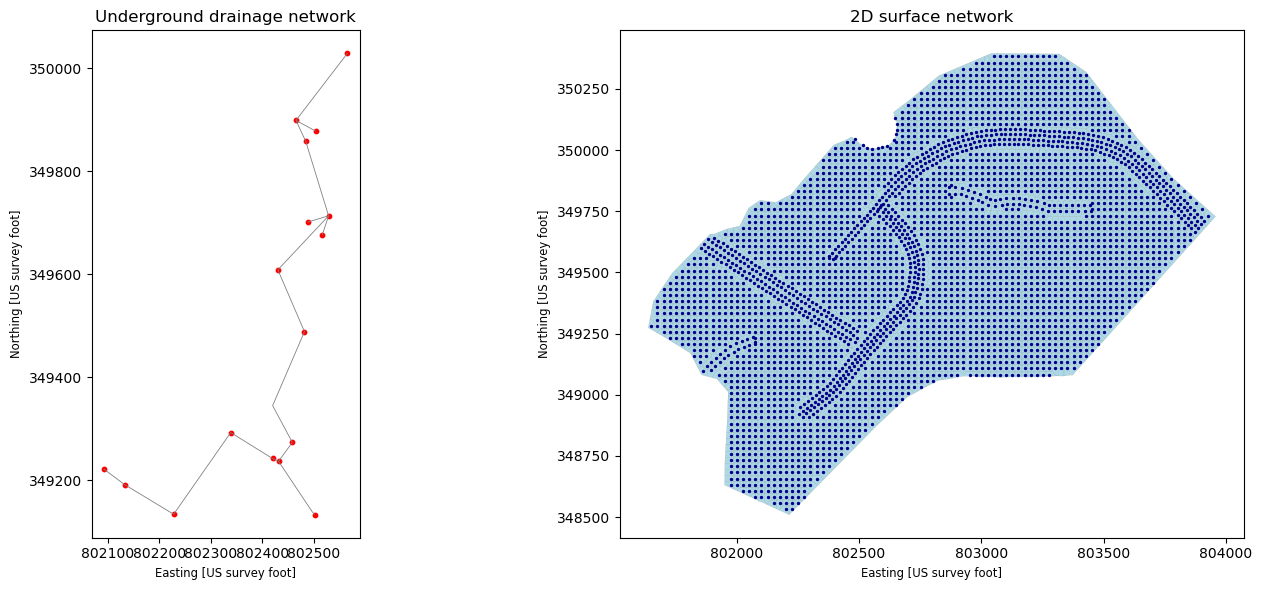

In [22]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)

nodes_1d_gdf.plot(
    ax=axes[0],
    color="red",
    markersize=10
)

links_1d_gdf.plot(
    ax=axes[0],
    color="grey",
    linewidth=0.6
)

axes[0].set_title("Underground drainage network")

mesh_2d_gdf.plot(
    ax=axes[1],
    color="lightblue",
    edgecolor="grey",
    linewidth=0.1
)

nodes_2d_gdf.plot(
    ax=axes[1],
    color="darkblue",
    markersize=2
)

axes[1].set_title("2D surface network")

plt.tight_layout()
plt.show()

# Processing the dynamic hydraulic observations

In [23]:
def clean_id(value):

    if pd.isna(value):

        return None

    try:

        number = float(value)

        if number.is_integer():

            return str(int(number))

    except:

        pass

    return str(value).strip()


def dynamic_variable_matrix(
    df,
    aliases,
    n_entities,
    ids,
    label
):

    time_col = find_column(
        df,
        [
            "timestep",
            "time_step",
            "time_index",
            "step",
            "time_idx"
        ]
    )

    entity_col = find_column(
        df,
        [
            "node_id",
            "node_idx",
            "node_index",
            "edge_id",
            "edge_idx",
            "edge_index",
            "link_id",
            "id"
        ]
    )

    value_col = find_column(
        df,
        aliases
    )

    variable_col = find_column(
        df,
        ["variable", "feature", "attribute"]
    )

    generic_value_col = find_column(
        df,
        ["value", "observation", "measurement"]
    )

    work = df.copy()

    if value_col is None and variable_col is not None:

        if generic_value_col is not None:

            alias_names = [
                normalize_name(x)
                for x in aliases
            ]

            variable_values = (
                work[variable_col]
                .astype(str)
                .map(normalize_name)
            )

            selected = work[
                variable_values.isin(alias_names)
            ]

            if len(selected) > 0:

                work = selected

                value_col = generic_value_col


    if (
        value_col is not None
        and entity_col is not None
        and time_col is not None
    ):

        work["_entity_key"] = work[entity_col].map(
            clean_id
        )

        id_map = {
            clean_id(value): i
            for i, value in enumerate(ids)
        }

        work["_entity_position"] = (
            work["_entity_key"].map(id_map)
        )

        if work["_entity_position"].isna().all():

            work["_entity_position"] = pd.to_numeric(
                work[entity_col],
                errors="coerce"
            )

            if (
                work["_entity_position"].min() == 0
                and work["_entity_position"].max() < n_entities
            ):

                work["_entity_position"] = (
                    work["_entity_position"].astype("Int64")
                )

            elif (
                work["_entity_position"].min() == 1
                and work["_entity_position"].max() <= n_entities
            ):

                work["_entity_position"] = (
                    work["_entity_position"] - 1
                ).astype("Int64")

        pivot = work.pivot_table(
            index=time_col,
            columns="_entity_position",
            values=value_col,
            aggfunc="mean"
        )

        pivot = pivot.reindex(
            columns=range(n_entities)
        )

        if pivot.shape[1] == n_entities:

            return pivot.to_numpy(dtype=np.float32)


    normalized_aliases = [
        normalize_name(x)
        for x in aliases
    ]

    wide_columns = []

    for col in work.columns:

        normalized = normalize_name(col)

        if any(
            alias in normalized
            for alias in normalized_aliases
        ):

            numbers = re.findall(r"\d+", normalized)

            if numbers:

                wide_columns.append(
                    (col, int(numbers[-1]))
                )

    if len(wide_columns) == n_entities:

        wide_columns = sorted(
            wide_columns,
            key=lambda x: x[1]
        )

        matrix = work[
            [x[0] for x in wide_columns]
        ].to_numpy(dtype=np.float32)

        return matrix


    metadata = [
        time_col,
        entity_col,
        variable_col,
        generic_value_col
    ]

    metadata = [
        x for x in metadata
        if x is not None
    ]

    remaining = [
        col for col in work.columns
        if col not in metadata
    ]

    numeric_columns = [
        col for col in remaining
        if pd.api.types.is_numeric_dtype(work[col])
    ]

    if len(numeric_columns) == n_entities:

        return work[numeric_columns].to_numpy(
            dtype=np.float32
        )


    if len(work) == n_entities:

        numeric_data = work.select_dtypes(
            include=np.number
        )

        if numeric_data.shape[1] > n_entities:

            return numeric_data.to_numpy(
                dtype=np.float32
            ).T


    raise ValueError(
        f"Unable to identify {label} as a time-by-entity matrix.\n"
        f"Detected columns: {df.columns.tolist()}\n"
        f"Expected entities: {n_entities}"
    )


def read_dynamic_variable(
    event_dir,
    filename,
    aliases,
    n_entities,
    ids,
    label
):

    path = event_dir / filename

    if not path.exists():

        return None

    df = pd.read_csv(
        path,
        low_memory=False
    )

    return dynamic_variable_matrix(
        df,
        aliases,
        n_entities,
        ids,
        label
    )

# Building the hydraulic incidence matrices

In [24]:
def build_incidence_matrix(pairs, n_nodes):

    n_edges = len(pairs)

    rows = np.repeat(
        np.arange(n_edges),
        2
    )

    cols = pairs.reshape(-1)

    values = np.tile(
        [-1.0, 1.0],
        n_edges
    )

    incidence = sparse.coo_matrix(
        (values, (rows, cols)),
        shape=(n_edges, n_nodes)
    ).tocsr()

    return incidence


INCIDENCE_1D = build_incidence_matrix(
    pairs_1d,
    N1
)

INCIDENCE_2D = build_incidence_matrix(
    pairs_2d,
    N2
)

def calculate_net_flow(flow_matrix, incidence):

    return np.asarray(
        (incidence.T @ flow_matrix.T).T,
        dtype=np.float32
    )
print("Hydraulic incidence matrices constructed.")

Hydraulic incidence matrices constructed.


# Calculate the simulation time interval

In [25]:
def infer_timestep_seconds(event_dir, default=60.0):

    path = event_dir / "timesteps.csv"

    if not path.exists():

        return default

    df = pd.read_csv(path)

    datetime_candidates = [
        "timestamp",
        "datetime",
        "date_time",
        "date",
        "time"
    ]

    col = find_column(
        df,
        datetime_candidates
    )

    if col is not None:

        parsed = pd.to_datetime(
            df[col],
            errors="coerce",
            utc=True
        )

        if parsed.notna().sum() >= 3:

            differences = (
                parsed.sort_values()
                .diff()
                .dt.total_seconds()
                .dropna()
            )

            positive = differences[differences > 0]

            if len(positive) > 0:

                return float(positive.median())


    seconds_col = find_column(
        df,
        [
            "elapsed_seconds",
            "time_seconds",
            "simulation_seconds"
        ]
    )

    if seconds_col is not None:

        values = pd.to_numeric(
            df[seconds_col],
            errors="coerce"
        ).dropna().to_numpy()

        if len(values) > 1:

            differences = np.diff(values)

            positive = differences[differences > 0]

            if len(positive) > 0:

                return float(np.median(positive))


    warnings.warn(
        "Could not infer actual simulation time. "
        f"Using the configured fallback of {default} seconds."
    )

    return default

# Load one complete rainfall event at a time

In [26]:
IDS_1D = entity_ids(
    static_1d_nodes,
    N1,
    "node"
)

IDS_2D = entity_ids(
    static_2d_nodes,
    N2,
    "node"
)

IDS_E1 = np.arange(len(pairs_1d))

IDS_E2 = np.arange(len(pairs_2d))


def load_event_arrays(event_dir):

    d1_level = read_dynamic_variable(
        event_dir,
        "1d_nodes_dynamic_all.csv",
        ["1d_node_water_level", "water_level"],
        N1,
        IDS_1D,
        "1D water level"
    )

    d1_inlet = read_dynamic_variable(
        event_dir,
        "1d_nodes_dynamic_all.csv",
        ["1d_node_inlet_flow", "inlet_flow"],
        N1,
        IDS_1D,
        "1D inlet flow"
    )

    d2_level = read_dynamic_variable(
        event_dir,
        "2d_nodes_dynamic_all.csv",
        ["2d_node_water_level", "water_level"],
        N2,
        IDS_2D,
        "2D water level"
    )

    rainfall = read_dynamic_variable(
        event_dir,
        "2d_nodes_dynamic_all.csv",
        ["rainfall_depth", "rainfall"],
        N2,
        IDS_2D,
        "rainfall"
    )

    volume = read_dynamic_variable(
        event_dir,
        "2d_nodes_dynamic_all.csv",
        ["water_volume", "volume"],
        N2,
        IDS_2D,
        "2D water volume"
    )

    flow1 = read_dynamic_variable(
        event_dir,
        "1d_edges_dynamic_all.csv",
        ["1d_edge_flow", "edge_flow", "flow"],
        len(pairs_1d),
        IDS_E1,
        "1D edge flow"
    )

    flow2 = read_dynamic_variable(
        event_dir,
        "2d_edges_dynamic_all.csv",
        ["2d_flow", "edge_flow", "flow"],
        len(pairs_2d),
        IDS_E2,
        "2D edge flow"
    )


    if d1_level is None or d2_level is None:

        raise ValueError(
            f"Missing essential water-level data in {event_dir.name}."
        )


    T = min(
        len(d1_level),
        len(d2_level)
    )

    if T < 2:

        raise ValueError("Not enough timesteps in this event.")


    def fit_length(array, shape):

        if array is None:

            return np.zeros(shape, dtype=np.float32)

        if len(array) < T:

            raise ValueError(
                "A dynamic variable contains fewer observations "
                "than the water-level target."
            )

        return np.asarray(
            array[:T],
            dtype=np.float32
        )


    arrays = {

        "level1": fit_length(
            d1_level,
            (T, N1)
        ),

        "inlet1": fit_length(
            d1_inlet,
            (T, N1)
        ),

        "level2": fit_length(
            d2_level,
            (T, N2)
        ),

        "rain2": fit_length(
            rainfall,
            (T, N2)
        ),

        "volume2": fit_length(
            volume,
            (T, N2)
        ),

        "flow1": fit_length(
            flow1,
            (T, len(pairs_1d))
        ),

        "flow2": fit_length(
            flow2,
            (T, len(pairs_2d))
        )
    }


    arrays["net1"] = calculate_net_flow(
        arrays["flow1"],
        INCIDENCE_1D
    )

    arrays["net2"] = calculate_net_flow(
        arrays["flow2"],
        INCIDENCE_2D
    )


    coupling_surface = np.zeros(
        (T, N2),
        dtype=np.float32
    )

    connection_counts = np.bincount(
        pairs_1d2d[:, 0],
        minlength=N1
    )

    for node1, node2 in pairs_1d2d:

        count = max(
            connection_counts[node1],
            1
        )

        coupling_surface[:, node2] -= (
            arrays["inlet1"][:, node1] / count
        )


    arrays["coupling_surface"] = coupling_surface

    arrays["dt"] = infer_timestep_seconds(
        event_dir
    )

    arrays["T"] = T

    return arrays


print("Event loading function created.")

Event loading function created.


# Construct the physics-informed mass balance

In [27]:
def calculate_physics_terms(arrays, timestep):

    dt = float(arrays["dt"])

    net1 = arrays["net1"][timestep]

    net2 = arrays["net2"][timestep]

    inlet1 = arrays["inlet1"][timestep]

    coupling2 = arrays["coupling_surface"][timestep]

    rainfall2 = arrays["rain2"][timestep]


    rainfall_rate = (
        (rainfall2 / 12.0)
        * area2
        / max(dt, 1e-6)
    )


    mass_rate_1d = net1 + inlet1

    mass_rate_2d = (
        net2
        + coupling2
        + rainfall_rate
    )


    mass_rate = np.concatenate([
        mass_rate_1d,
        mass_rate_2d
    ]).astype(np.float32)


    return {

        "mass_rate": mass_rate,

        "storage_area": STORAGE_AREA.copy(),

        "dt": dt,

        "physics_mask": (
    STORAGE_AREA_VALID
    & np.isfinite(mass_rate)
)
    }

print("Hydraulic mass balance function created.")

Hydraulic mass balance function created.


# Create the graph input features

In [28]:
DYNAMIC_FEATURE_NAMES = [
    "current_water_level",
    "rainfall",
    "water_volume_per_area",
    "net_hydraulic_flow",
    "inlet_flow"
]


ALL_FEATURE_NAMES = (
    STATIC_FEATURE_NAMES
    + DYNAMIC_FEATURE_NAMES
)


def construct_node_features(arrays, timestep):

    level1 = arrays["level1"][timestep]

    level2 = arrays["level2"][timestep]


    current_level = np.concatenate([
        level1,
        level2
    ])


    rain_combined = np.concatenate([
        np.zeros(N1, dtype=np.float32),
        arrays["rain2"][timestep]
    ])


    volume_per_area = (
        arrays["volume2"][timestep]
        / np.maximum(area2, 1e-6)
    )


    volume_combined = np.concatenate([
        np.zeros(N1, dtype=np.float32),
        volume_per_area
    ])


    net_combined = np.concatenate([
        arrays["net1"][timestep]
        + arrays["inlet1"][timestep],

        arrays["net2"][timestep]
        + arrays["coupling_surface"][timestep]
    ])


    inlet_combined = np.concatenate([
        arrays["inlet1"][timestep],
        -arrays["coupling_surface"][timestep]
    ])


    dynamic_features = np.column_stack([
        current_level,
        rain_combined,
        volume_combined,
        net_combined,
        inlet_combined
    ])


    features = np.column_stack([
        STATIC_FEATURES,
        dynamic_features
    ])


    return np.nan_to_num(
        features,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    ).astype(np.float32)

# Generate training samples from a rainfall event

In [29]:
def create_event_samples(
    event_dir,
    number_of_samples=6,
    split="train",
    seed=42
):

    arrays = load_event_arrays(event_dir)

    T = arrays["T"]

    rng = np.random.default_rng(seed)


    if split == "train":

        times = rng.choice(
            np.arange(T - 1),
            size=min(number_of_samples, T - 1),
            replace=False
        )

    else:

        times = np.linspace(
            0,
            T - 2,
            num=min(number_of_samples, T - 1),
            dtype=int
        )


    samples = []


    for t in sorted(times):

        x = construct_node_features(
            arrays,
            t
        )


        current_level = np.concatenate([
            arrays["level1"][t],
            arrays["level2"][t]
        ])


        next_level = np.concatenate([
            arrays["level1"][t + 1],
            arrays["level2"][t + 1]
        ])


        target_delta = next_level - current_level


        physical = calculate_physics_terms(
            arrays,
            t
        )


        mass_rate = physical["mass_rate"]

        valid = physical["physics_mask"]


        if np.any(valid):

            mass_scale = max(
                float(np.mean(np.abs(mass_rate[valid]))),
                1.0
            )

        else:

            mass_scale = 1.0


        sample = {

            "X": x,

            "y": target_delta.astype(np.float32),

            "current_level": current_level.astype(np.float32),

            "target_level": next_level.astype(np.float32),

            "mass_rate": mass_rate,

            "storage_area": physical["storage_area"],

            "dt": physical["dt"],

            "physics_mask": valid,

            "target_mask": (
                np.isfinite(target_delta)
                & np.isfinite(current_level)
            ),

            "mass_scale": mass_scale,

            "event_id": event_dir.name,

            "timestep": int(t)

        }


        samples.append(sample)


    del arrays

    gc.collect()

    return samples

# Split the rainfall events

In [30]:
rng = np.random.default_rng(SEED)

event_paths = np.array(
    train_events,
    dtype=object
)

rng.shuffle(event_paths)

n_events = len(event_paths)

n_train = int(n_events * 0.70)

n_validation = int(n_events * 0.15)

train_event_paths = list(
    event_paths[:n_train]
)

validation_event_paths = list(
    event_paths[n_train:n_train + n_validation]
)

evaluation_event_paths = list(
    event_paths[n_train + n_validation:]
)


MAX_TRAIN_EVENTS = None
MAX_VALIDATION_EVENTS = None
MAX_EVALUATION_EVENTS = None

if MAX_TRAIN_EVENTS is not None:

    train_event_paths = train_event_paths[
        :MAX_TRAIN_EVENTS
    ]

if MAX_VALIDATION_EVENTS is not None:

    validation_event_paths = validation_event_paths[
        :MAX_VALIDATION_EVENTS
    ]

if MAX_EVALUATION_EVENTS is not None:

    evaluation_event_paths = evaluation_event_paths[
        :MAX_EVALUATION_EVENTS
    ]


print("Training events:", len(train_event_paths))

print("Validation events:", len(validation_event_paths))

print("Independent evaluation events:", len(evaluation_event_paths))

Training events: 47
Validation events: 10
Independent evaluation events: 11


# Generate training, validation and evaluation samples

In [31]:
TRAIN_SAMPLES_PER_EVENT = 6

EVALUATION_SAMPLES_PER_EVENT = 12


def prepare_dataset(event_paths, split, samples_per_event):

    all_samples = []

    for i, event_path in enumerate(event_paths):

        print(
            f"Processing {split} event "
            f"{i + 1}/{len(event_paths)}: "
            f"{event_path.name}"
        )

        event_samples = create_event_samples(
            event_path,
            number_of_samples=samples_per_event,
            split=split,
            seed=SEED + i
        )

        all_samples.extend(event_samples)

        gc.collect()


    return all_samples


train_samples = prepare_dataset(
    train_event_paths,
    "train",
    TRAIN_SAMPLES_PER_EVENT
)

validation_samples = prepare_dataset(
    validation_event_paths,
    "validation",
    EVALUATION_SAMPLES_PER_EVENT
)

evaluation_samples = prepare_dataset(
    evaluation_event_paths,
    "evaluation",
    EVALUATION_SAMPLES_PER_EVENT
)

print("\nTotal training samples:", len(train_samples))
print("Total validation samples:", len(validation_samples))
print("Total evaluation samples:", len(evaluation_samples))

Processing train event 1/47: event_27
Processing train event 2/47: event_95
Processing train event 3/47: event_6
Processing train event 4/47: event_74
Processing train event 5/47: event_89
Processing train event 6/47: event_87
Processing train event 7/47: event_23
Processing train event 8/47: event_21
Processing train event 9/47: event_10
Processing train event 10/47: event_90
Processing train event 11/47: event_46
Processing train event 12/47: event_60
Processing train event 13/47: event_96
Processing train event 14/47: event_77
Processing train event 15/47: event_91
Processing train event 16/47: event_39
Processing train event 17/47: event_7
Processing train event 18/47: event_2
Processing train event 19/47: event_32
Processing train event 20/47: event_56
Processing train event 21/47: event_38
Processing train event 22/47: event_54
Processing train event 23/47: event_36
Processing train event 24/47: event_92
Processing train event 25/47: event_25
Processing train event 26/47: event_7

# Check the prepared research data

In [32]:
sample = train_samples[0]

print("Input shape:", sample["X"].shape)

print("Target shape:", sample["y"].shape)

print("Current water levels:", sample["current_level"].shape)

print("Physical mass balance:", sample["mass_rate"].shape)

print("Storage area:", sample["storage_area"].shape)

print("Simulation timestep:", sample["dt"])

print("Event:", sample["event_id"])

print("\nAvailable model input variables:")

for name in ALL_FEATURE_NAMES:

    print(name)

Input shape: (3733, 19)
Target shape: (3733,)
Current water levels: (3733,)
Physical mass balance: (3733,)
Storage area: (3733,)
Simulation timestep: 300.0
Event: event_27

Available model input variables:
x_coordinate
y_coordinate
elevation
minimum_elevation
area
roughness
depth
invert_elevation
curvature
flow_accumulation
aspect_sin
aspect_cos
is_1d
is_2d
current_water_level
rainfall
water_volume_per_area
net_hydraulic_flow
inlet_flow


# Normalizing the input data

In [33]:
feature_scaler = StandardScaler()

for sample in train_samples:

    feature_scaler.partial_fit(
        sample["X"]
    )


all_training_targets = np.concatenate([
    sample["y"][sample["target_mask"]]
    for sample in train_samples
])


TARGET_MEAN = float(
    np.mean(all_training_targets)
)

TARGET_STD = float(
    np.std(all_training_targets)
)

TARGET_STD = max(TARGET_STD, 1e-6)


def pack_samples(samples):

    X = np.stack([
        feature_scaler.transform(s["X"])
        for s in samples
    ]).astype(np.float32)


    y = np.stack([
        s["y"]
        for s in samples
    ]).astype(np.float32)


    current = np.stack([
        s["current_level"]
        for s in samples
    ]).astype(np.float32)


    target_level = np.stack([
        s["target_level"]
        for s in samples
    ]).astype(np.float32)


    mass_rate = np.stack([
        s["mass_rate"]
        for s in samples
    ]).astype(np.float32)


    storage_area = np.stack([
        s["storage_area"]
        for s in samples
    ]).astype(np.float32)


    physics_mask = np.stack([
        s["physics_mask"]
        for s in samples
    ]).astype(bool)


    target_mask = np.stack([
        s["target_mask"]
        for s in samples
    ]).astype(bool)


    dt = np.array([
        s["dt"]
        for s in samples
    ], dtype=np.float32)


    mass_scale = np.array([
        s["mass_scale"]
        for s in samples
    ], dtype=np.float32)


    return {

        "X": np.nan_to_num(X),

        "y": np.nan_to_num(y),

        "current": np.nan_to_num(current),

        "target_level": np.nan_to_num(target_level),

        "mass_rate": np.nan_to_num(mass_rate),

        "storage_area": np.nan_to_num(storage_area),

        "physics_mask": physics_mask,

        "target_mask": target_mask,

        "dt": dt,

        "mass_scale": mass_scale

    }

train_data = pack_samples(train_samples)
validation_data = pack_samples(validation_samples)
evaluation_data = pack_samples(evaluation_samples)
print("Training input:", train_data["X"].shape)
print("Validation input:", validation_data["X"].shape)
print("Evaluation input:", evaluation_data["X"].shape)
print("Target mean:", TARGET_MEAN)
print("Target standard deviation:", TARGET_STD)

Training input: (282, 3733, 19)
Validation input: (120, 3733, 19)
Evaluation input: (132, 3733, 19)
Target mean: -0.0004172522167209536
Target standard deviation: 0.013493886217474937


# Define the Graph Neural Network layers

In [34]:
class GraphConvolution(nn.Module):

    def __init__(self, input_dim, output_dim):

        super().__init__()

        self.self_linear = nn.Linear(
            input_dim,
            output_dim
        )

        self.neighbour_linear = nn.Linear(
            input_dim,
            output_dim
        )


    def forward(self, x, edge_index, edge_weight):

        source = edge_index[0]

        destination = edge_index[1]

        batch_size, n_nodes, _ = x.shape


        messages = x[:, source, :]

        messages = (
            messages
            * edge_weight.view(1, -1, 1)
        )


        aggregate = torch.zeros_like(x)

        aggregate.index_add_(
            1,
            destination,
            messages
        )


        degree = torch.zeros(
            n_nodes,
            dtype=x.dtype,
            device=x.device
        )

        degree.index_add_(
            0,
            destination,
            edge_weight
        )


        aggregate = aggregate / (
            degree.view(1, n_nodes, 1) + 1e-8
        )


        output = (
            self.self_linear(x)
            + self.neighbour_linear(aggregate)
        )


        return output


class PhysicsInformedGNN(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=32,
        dropout=0.10
    ):

        super().__init__()

        self.gnn1 = GraphConvolution(
            input_dim,
            hidden_dim
        )

        self.gnn2 = GraphConvolution(
            hidden_dim,
            hidden_dim
        )

        self.norm1 = nn.LayerNorm(hidden_dim)

        self.norm2 = nn.LayerNorm(hidden_dim)

        self.dropout = nn.Dropout(dropout)

        self.output_layer = nn.Sequential(

            nn.Linear(hidden_dim, 16),

            nn.ReLU(),

            nn.Linear(16, 1)

        )


    def forward(self, x, edge_index, edge_weight):

        x = self.gnn1(
            x,
            edge_index,
            edge_weight
        )

        x = self.norm1(x)

        x = F.relu(x)

        x = self.dropout(x)


        x = self.gnn2(
            x,
            edge_index,
            edge_weight
        )

        x = self.norm2(x)

        x = F.relu(x)

        output = self.output_layer(x).squeeze(-1)


        return output


model = PhysicsInformedGNN(
    input_dim=len(ALL_FEATURE_NAMES),
    hidden_dim=32
).to(DEVICE)


print(model)

PhysicsInformedGNN(
  (gnn1): GraphConvolution(
    (self_linear): Linear(in_features=19, out_features=32, bias=True)
    (neighbour_linear): Linear(in_features=19, out_features=32, bias=True)
  )
  (gnn2): GraphConvolution(
    (self_linear): Linear(in_features=32, out_features=32, bias=True)
    (neighbour_linear): Linear(in_features=32, out_features=32, bias=True)
  )
  (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (output_layer): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)


# Define the physics-informed loss function

In [35]:
def calculate_model_loss(
    prediction,
    target,
    target_mask,
    storage_area,
    mass_rate,
    dt,
    physics_mask,
    mass_scale,
    physics_weight
):

    normalized_target = (
        target - TARGET_MEAN
    ) / TARGET_STD


    squared_error = (
        prediction - normalized_target
    ) ** 2


    data_loss = (
        squared_error * target_mask.float()
    ).sum() / (
        target_mask.float().sum() + 1e-8
    )


    predicted_delta = (
        prediction * TARGET_STD
        + TARGET_MEAN
    )


    predicted_volume_rate = (
        storage_area
        * predicted_delta
        / dt.unsqueeze(1).clamp_min(1e-6)
    )


    physical_residual = (
        predicted_volume_rate - mass_rate
    )


    normalized_residual = (
        physical_residual
        / mass_scale.unsqueeze(1).clamp_min(1e-6)
    )


    physics_squared_error = (
        normalized_residual ** 2
    )


    physics_loss = (
        physics_squared_error
        * physics_mask.float()
    ).sum() / (
        physics_mask.float().sum() + 1e-8
    )


    total_loss = (
        data_loss
        + physics_weight * physics_loss
    )


    return total_loss, data_loss, physics_loss

# Define the training procedure

In [36]:
HIDDEN_DIM = 32

DROPOUT = 0.10

LEARNING_RATE = 0.001

WEIGHT_DECAY = 1e-5

BATCH_SIZE = 4

EPOCHS = 20

PATIENCE = 5

PHYSICS_WEIGHT = 0.02


def get_batch(data, indices):

    return {

        key: torch.as_tensor(
            value[indices],
            dtype=torch.float32,
            device=DEVICE
        )

        for key, value in data.items()

    }


def validation_rmse(model, data):

    model.eval()

    predictions = []

    actual = []

    with torch.no_grad():

        for start in range(
            0,
            len(data["X"]),
            BATCH_SIZE
        ):

            idx = np.arange(
                start,
                min(start + BATCH_SIZE, len(data["X"]))
            )

            batch = get_batch(
                data,
                idx
            )

            prediction = model(
                batch["X"],
                EDGE_INDEX_TENSOR,
                EDGE_WEIGHT_TENSOR
            )


            prediction = (
                prediction * TARGET_STD
                + TARGET_MEAN
            )


            predictions.append(
                prediction.cpu().numpy()
            )

            actual.append(
                batch["y"].cpu().numpy()
            )


    predictions = np.concatenate(predictions)

    actual = np.concatenate(actual)

    mask = np.isfinite(actual)

    rmse = np.sqrt(
        np.mean(
            (predictions[mask] - actual[mask]) ** 2
        )
    )

    return float(rmse)


def train_model(
    train_data,
    validation_data,
    physics_weight,
    name
):

    torch.manual_seed(SEED)

    model = PhysicsInformedGNN(
        input_dim=len(ALL_FEATURE_NAMES),
        hidden_dim=HIDDEN_DIM,
        dropout=DROPOUT
    ).to(DEVICE)


    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )


    best_rmse = float("inf")

    best_state = None

    patience_counter = 0

    history = []


    n_samples = len(train_data["X"])


    for epoch in range(EPOCHS):

        model.train()

        indices = np.random.permutation(
            n_samples
        )

        epoch_losses = []


        for start in range(
            0,
            n_samples,
            BATCH_SIZE
        ):

            batch_indices = indices[
                start:start + BATCH_SIZE
            ]

            batch = get_batch(
                train_data,
                batch_indices
            )


            optimizer.zero_grad()


            prediction = model(
                batch["X"],
                EDGE_INDEX_TENSOR,
                EDGE_WEIGHT_TENSOR
            )


            total_loss, data_loss, physical_loss = (
                calculate_model_loss(

                    prediction,

                    batch["y"],

                    batch["target_mask"],

                    batch["storage_area"],

                    batch["mass_rate"],

                    batch["dt"],

                    batch["physics_mask"],

                    batch["mass_scale"],

                    physics_weight
                )
            )


            total_loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            epoch_losses.append(
                total_loss.item()
            )


        val_rmse = validation_rmse(
            model,
            validation_data
        )


        train_loss = float(
            np.mean(epoch_losses)
        )


        history.append({

            "epoch": epoch + 1,

            "train_loss": train_loss,

            "validation_rmse": val_rmse

        })


        print(
            f"{name} | "
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Loss: {train_loss:.6f} | "
            f"Validation RMSE: {val_rmse:.6f} ft"
        )


        if val_rmse < best_rmse:

            best_rmse = val_rmse

            best_state = deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1


        if patience_counter >= PATIENCE:

            print("Early stopping activated.")

            break


    if best_state is None:

        raise RuntimeError(
            f"Training failed for {name}."
        )


    model.load_state_dict(best_state)

    return model, pd.DataFrame(history)

# Train the conventional GNN and physics-informed GNN

In [37]:
history_models = {}

trained_models = {}


print("Training conventional GNN")

model_baseline, history_baseline = train_model(
    train_data,
    validation_data,
    physics_weight=0.0,
    name="Conventional GNN"
)

trained_models["Conventional GNN"] = model_baseline

history_models["Conventional GNN"] = history_baseline


print("\nTraining physics-informed GNN")

model_physics, history_physics = train_model(
    train_data,
    validation_data,
    physics_weight=PHYSICS_WEIGHT,
    name="Physics-Informed GNN"
)

trained_models["Physics-Informed GNN"] = model_physics

history_models["Physics-Informed GNN"] = history_physics
print("\nBoth models have finished training.")

Training conventional GNN
Conventional GNN | Epoch 1/20 | Loss: 1.005035 | Validation RMSE: 0.015411 ft
Conventional GNN | Epoch 2/20 | Loss: 0.968497 | Validation RMSE: 0.015356 ft
Conventional GNN | Epoch 3/20 | Loss: 0.954481 | Validation RMSE: 0.015273 ft
Conventional GNN | Epoch 4/20 | Loss: 0.950520 | Validation RMSE: 0.015061 ft
Conventional GNN | Epoch 5/20 | Loss: 0.896273 | Validation RMSE: 0.014750 ft
Conventional GNN | Epoch 6/20 | Loss: 0.884795 | Validation RMSE: 0.014582 ft
Conventional GNN | Epoch 7/20 | Loss: 0.864665 | Validation RMSE: 0.014509 ft
Conventional GNN | Epoch 8/20 | Loss: 0.851444 | Validation RMSE: 0.014527 ft
Conventional GNN | Epoch 9/20 | Loss: 0.843811 | Validation RMSE: 0.014477 ft
Conventional GNN | Epoch 10/20 | Loss: 0.846133 | Validation RMSE: 0.014367 ft
Conventional GNN | Epoch 11/20 | Loss: 0.839221 | Validation RMSE: 0.014352 ft
Conventional GNN | Epoch 12/20 | Loss: 0.835495 | Validation RMSE: 0.014310 ft
Conventional GNN | Epoch 13/20 | Lo

# Visualize the training process

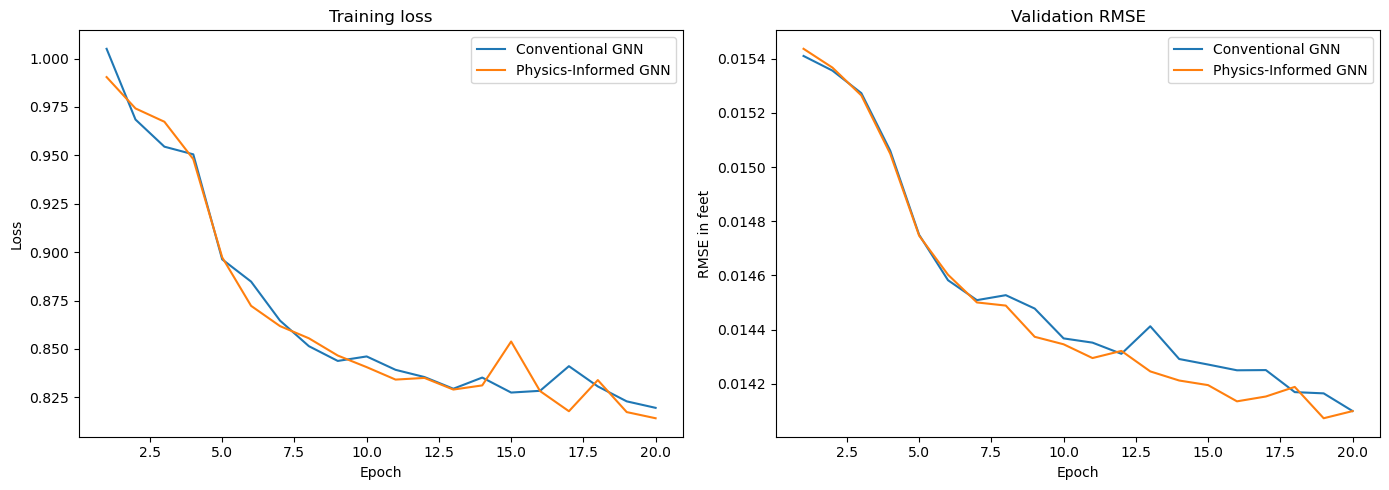

In [38]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


for name, history in history_models.items():

    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        label=name
    )

    axes[1].plot(
        history["epoch"],
        history["validation_rmse"],
        label=name
    )
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].set_title("Validation RMSE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("RMSE in feet")
axes[1].legend()
plt.tight_layout()
plt.show()

# Develop prediction and evaluation functions

In [39]:
def predict_dataset(model, data):

    model.eval()

    predictions = []

    with torch.no_grad():

        for start in range(
            0,
            len(data["X"]),
            BATCH_SIZE
        ):

            indices = np.arange(
                start,
                min(start + BATCH_SIZE, len(data["X"]))
            )

            batch = get_batch(
                data,
                indices
            )


            prediction = model(
                batch["X"],
                EDGE_INDEX_TENSOR,
                EDGE_WEIGHT_TENSOR
            )


            prediction = (
                prediction * TARGET_STD
                + TARGET_MEAN
            )


            predictions.append(
                prediction.cpu().numpy()
            )


    predicted_delta = np.concatenate(
        predictions,
        axis=0
    )


    predicted_next_level = (
        data["current"] + predicted_delta
    )


    return {

        "predicted_delta": predicted_delta,

        "predicted_level": predicted_next_level,

        "actual_level": data["target_level"],

        "current_level": data["current"]

    }


def calculate_metrics(y_true, y_pred):

    mask = (
        np.isfinite(y_true)
        & np.isfinite(y_pred)
    )

    y_true = y_true[mask]

    y_pred = y_pred[mask]

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    denominator = np.sum(
        (y_true - np.mean(y_true)) ** 2
    )

    numerator = np.sum(
        (y_true - y_pred) ** 2
    )

    nse = (
        1 - numerator / denominator
        if denominator > 0
        else np.nan
    )

    return {

        "RMSE_ft": rmse,

        "MAE_ft": mae,

        "R2": r2,

        "NSE": nse,

        "Observations": len(y_true)

    }

# Evaluate the models on the independent evaluation events

In [40]:
model_predictions = {}

for name, model in trained_models.items():

    model_predictions[name] = predict_dataset(
        model,
        evaluation_data
    )


baseline_prediction = evaluation_data["current"]


model_predictions["Persistence Baseline"] = {

    "predicted_level": baseline_prediction,

    "actual_level": evaluation_data["target_level"]

}


node_groups = {

    "All Nodes": np.arange(N_TOTAL),

    "1D Drainage Nodes": np.arange(N1),

    "2D Surface Nodes": np.arange(N1, N_TOTAL)

}


results = []


for model_name, output in model_predictions.items():

    for group_name, indices in node_groups.items():

        metrics = calculate_metrics(
            output["actual_level"][:, indices].ravel(),
            output["predicted_level"][:, indices].ravel()
        )


        results.append({

            "Model": model_name,

            "Node_Group": group_name,

            **metrics

        })


results_df = pd.DataFrame(results)

display(
    results_df.round(5)
)

,Model,Node_Group,RMSE_ft,MAE_ft,R2,NSE,Observations
0,Conventional GNN,All Nodes,0.01797,0.00591,1.00000,1.00000,492756
1,Conventional GNN,1D Drainage Nodes,0.16346,0.03830,0.99991,0.99991,2244
2,Conventional GNN,2D Surface Nodes,0.01422,0.00576,1.00000,1.00000,490512
3,Physics-Informed GNN,All Nodes,0.01792,0.00549,1.00000,1.00000,492756
4,Physics-Informed GNN,1D Drainage Nodes,0.16322,0.03494,0.99991,0.99991,2244
5,Physics-Informed GNN,2D Surface Nodes,0.01416,0.00536,1.00000,1.00000,490512
6,Persistence Baseline,All Nodes,0.01930,0.00551,1.00000,1.00000,492756
7,Persistence Baseline,1D Drainage Nodes,0.16425,0.03416,0.99991,0.99991,2244
8,Persistence Baseline,2D Surface Nodes,0.01584,0.00538,1.00000,1.00000,490512


# Calculate physical consistency on the evaluation data

In [41]:
def calculate_physics_residual(
    predicted_delta,
    data
):

    residual = (
        data["storage_area"]
        * predicted_delta
        / np.maximum(data["dt"][:, None], 1e-6)
        - data["mass_rate"]
    )


    mask = data["physics_mask"]

    scales = np.maximum(
        data["mass_scale"][:, None],
        1e-6
    )


    normalized_residual = residual / scales

    values = normalized_residual[mask]


    return {

        "Mean_Absolute_Normalized_Residual": np.mean(
            np.abs(values)
        ),

        "RMSE_Normalized_Residual": np.sqrt(
            np.mean(values ** 2)
        )

    }


physics_results = []


for name, model in trained_models.items():

    output = model_predictions[name]

    residual_metrics = calculate_physics_residual(
        output["predicted_delta"],
        evaluation_data
    )


    physics_results.append({

        "Model": name,

        **residual_metrics

    })

physics_results_df = pd.DataFrame(
    physics_results
)

display(
    physics_results_df.round(6)
)

,Model,Mean_Absolute_Normalized_Residual,RMSE_Normalized_Residual
0,Conventional GNN,0.005902,0.079206
1,Physics-Informed GNN,0.004707,0.079154


# Comparing the models visually

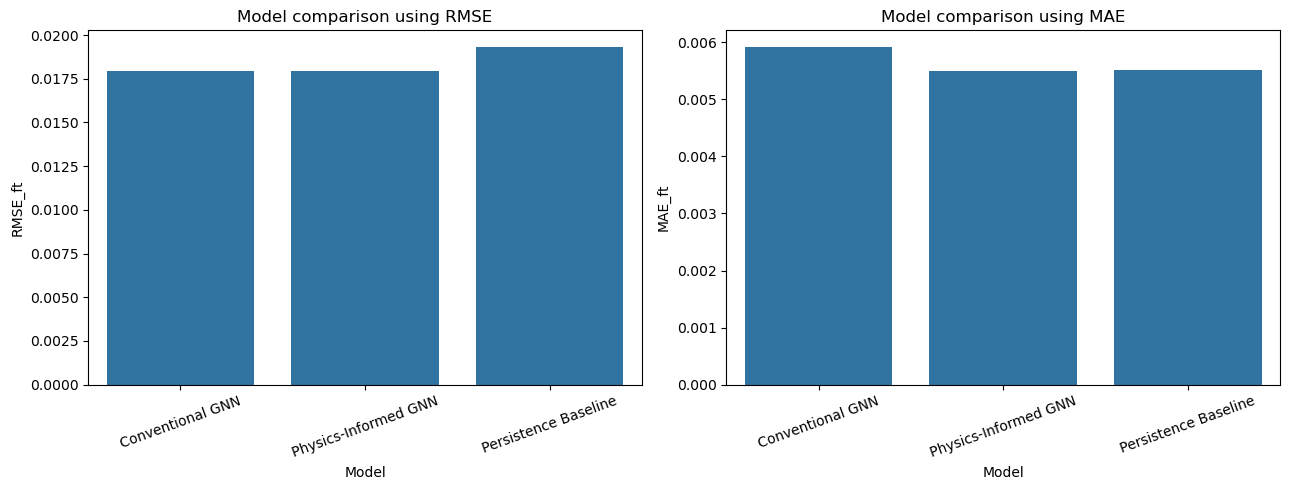

In [42]:
comparison = results_df[
    results_df["Node_Group"] == "All Nodes"
].copy()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)
sns.barplot(
    data=comparison,
    x="Model",
    y="RMSE_ft",
    ax=axes[0]
)

axes[0].set_title("Model comparison using RMSE")

axes[0].tick_params(
    axis="x",
    rotation=20
)
sns.barplot(
    data=comparison,
    x="Model",
    y="MAE_ft",
    ax=axes[1]
)
axes[1].set_title("Model comparison using MAE")
axes[1].tick_params(
    axis="x",
    rotation=20
)
plt.tight_layout()
plt.show()

# Analyzing the prediction errors

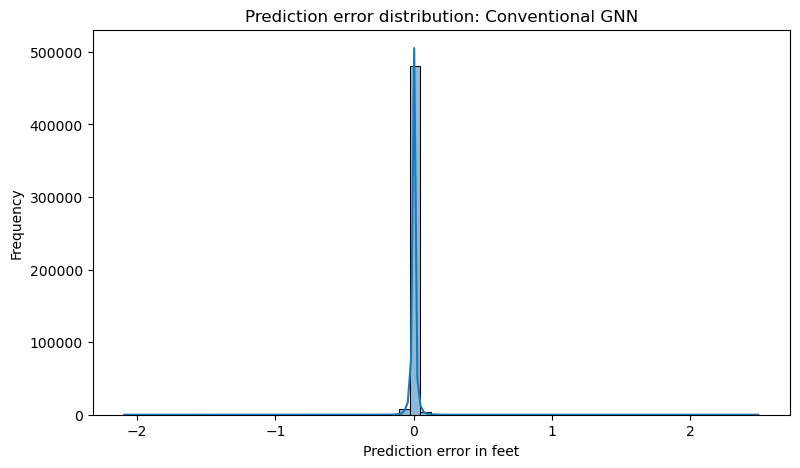

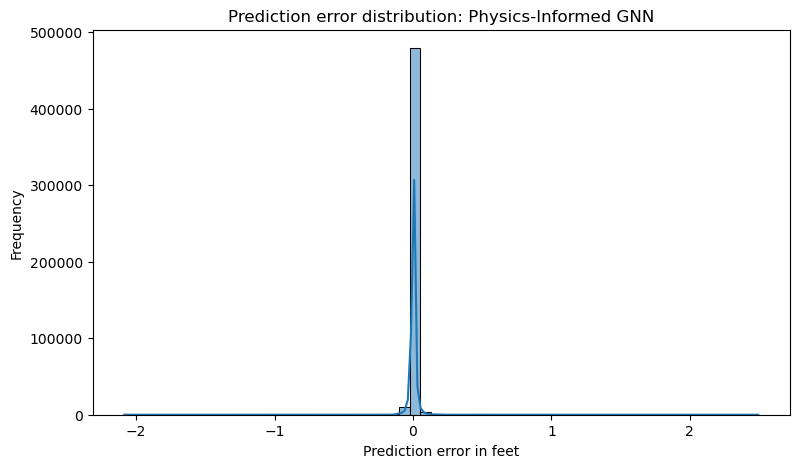

In [43]:
for model_name in [
    "Conventional GNN",
    "Physics-Informed GNN"
]:

    output = model_predictions[model_name]

    errors = (
        output["predicted_level"]
        - output["actual_level"]
    )


    plt.figure(figsize=(9, 5))

    sns.histplot(
        errors.ravel(),
        bins=60,
        kde=True
    )

    plt.title(
        f"Prediction error distribution: {model_name}"
    )

    plt.xlabel("Prediction error in feet")

    plt.ylabel("Frequency")

    plt.show()

# Plot observed against predicted water levels

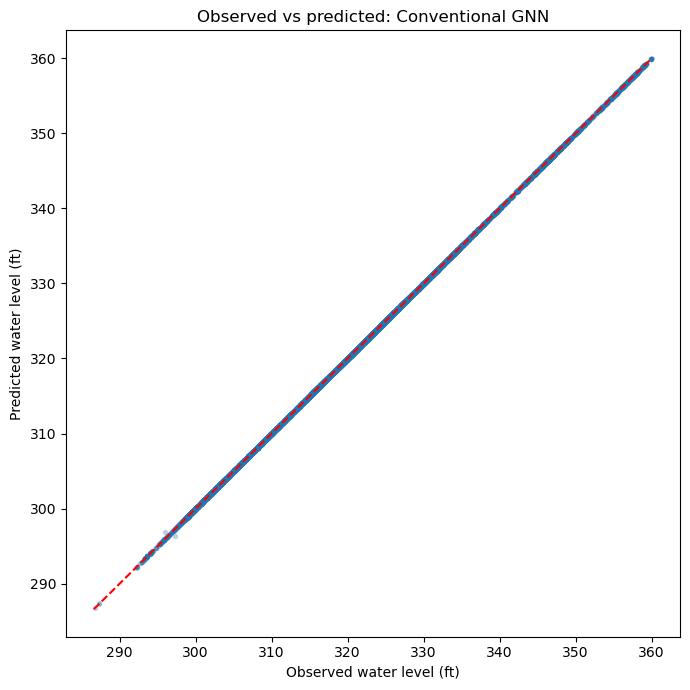

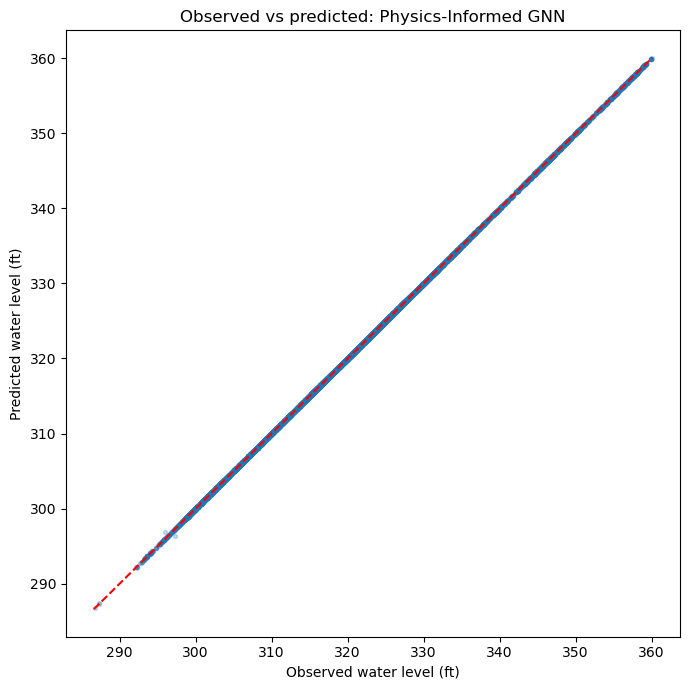

In [44]:
for model_name in [
    "Conventional GNN",
    "Physics-Informed GNN"
]:

    output = model_predictions[model_name]

    true_values = output["actual_level"].ravel()

    predicted_values = output["predicted_level"].ravel()


    sample_size = min(
        15000,
        len(true_values)
    )

    rng = np.random.default_rng(SEED)

    selected = rng.choice(
        len(true_values),
        size=sample_size,
        replace=False
    )


    plt.figure(figsize=(7, 7))

    plt.scatter(
        true_values[selected],
        predicted_values[selected],
        alpha=0.25,
        s=8
    )


    minimum = min(
        true_values.min(),
        predicted_values.min()
    )

    maximum = max(
        true_values.max(),
        predicted_values.max()
    )


    plt.plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle="--",
        color="red"
    )


    plt.xlabel("Observed water level (ft)")

    plt.ylabel("Predicted water level (ft)")

    plt.title(
        f"Observed vs predicted: {model_name}"
    )

    plt.tight_layout()

    plt.show()

# Geospatial flood hotspot identification

In [45]:
SURFACE_LEVEL_IS_DEPTH = True
FLOOD_DEPTH_THRESHOLD_FT = 0.5
print(
    "Surface water level represents depth:",
    SURFACE_LEVEL_IS_DEPTH
)

print(
    "Illustrative analysis threshold:",
    FLOOD_DEPTH_THRESHOLD_FT,
    "feet"
)

Surface water level represents depth: True
Illustrative analysis threshold: 0.5 feet


# Calculate predicted and observed surface flood depths

In [46]:
physics_output = model_predictions[
    "Physics-Informed GNN"
]


predicted_surface_level = (
    physics_output["predicted_level"][:, N1:]
)

observed_surface_level = (
    physics_output["actual_level"][:, N1:]
)


def convert_to_flood_depth(level):

    if SURFACE_LEVEL_IS_DEPTH:

        depth = level

    else:

        depth = (
            level
            - GROUND_ELEVATION_2D.reshape(1, -1)
        )


    return np.maximum(
        depth,
        0
    )


predicted_depth = convert_to_flood_depth(
    predicted_surface_level
)

observed_depth = convert_to_flood_depth(
    observed_surface_level
)


maximum_predicted_depth = np.nanmax(
    predicted_depth,
    axis=0
)

maximum_observed_depth = np.nanmax(
    observed_depth,
    axis=0
)


hotspot_df = pd.DataFrame({

    "node_index": np.arange(N2),

    "x_coordinate": x2,

    "y_coordinate": y2,

    "maximum_predicted_depth_ft": maximum_predicted_depth,

    "maximum_observed_depth_ft": maximum_observed_depth,

    "prediction_error_ft": (
        maximum_predicted_depth
        - maximum_observed_depth
    ),

    "potential_hotspot": (
        maximum_predicted_depth
        >= FLOOD_DEPTH_THRESHOLD_FT
    )

})


display(
    hotspot_df.head(10)
)

print(
    "Potential surface hotspots:",
    hotspot_df["potential_hotspot"].sum()
)

,node_index,x_coordinate,y_coordinate,maximum_predicted_depth_ft,maximum_observed_depth_ft,prediction_error_ft,potential_hotspot
0,0,803051.5625,350382.4375,329.976654,329.965057,0.011597,True
1,1,803076.5625,350382.4375,330.008972,330.001862,0.007111,True
2,2,803101.5625,350382.4375,329.920502,329.909088,0.011414,True
3,3,803126.5625,350382.4375,329.460541,329.452637,0.007904,True
4,4,803151.5625,350382.4375,328.528229,328.520172,0.008057,True
5,5,803176.5625,350382.4375,328.263031,328.254456,0.008575,True
6,6,803201.5625,350382.4375,327.754517,327.742798,0.011719,True
7,7,803226.5625,350382.4375,327.474701,327.458191,0.016510,True
8,8,803251.5625,350382.4375,327.530670,327.512878,0.017792,True
9,9,803276.5625,350382.4375,328.714783,328.689178,0.025604,True


Potential surface hotspots: 3716


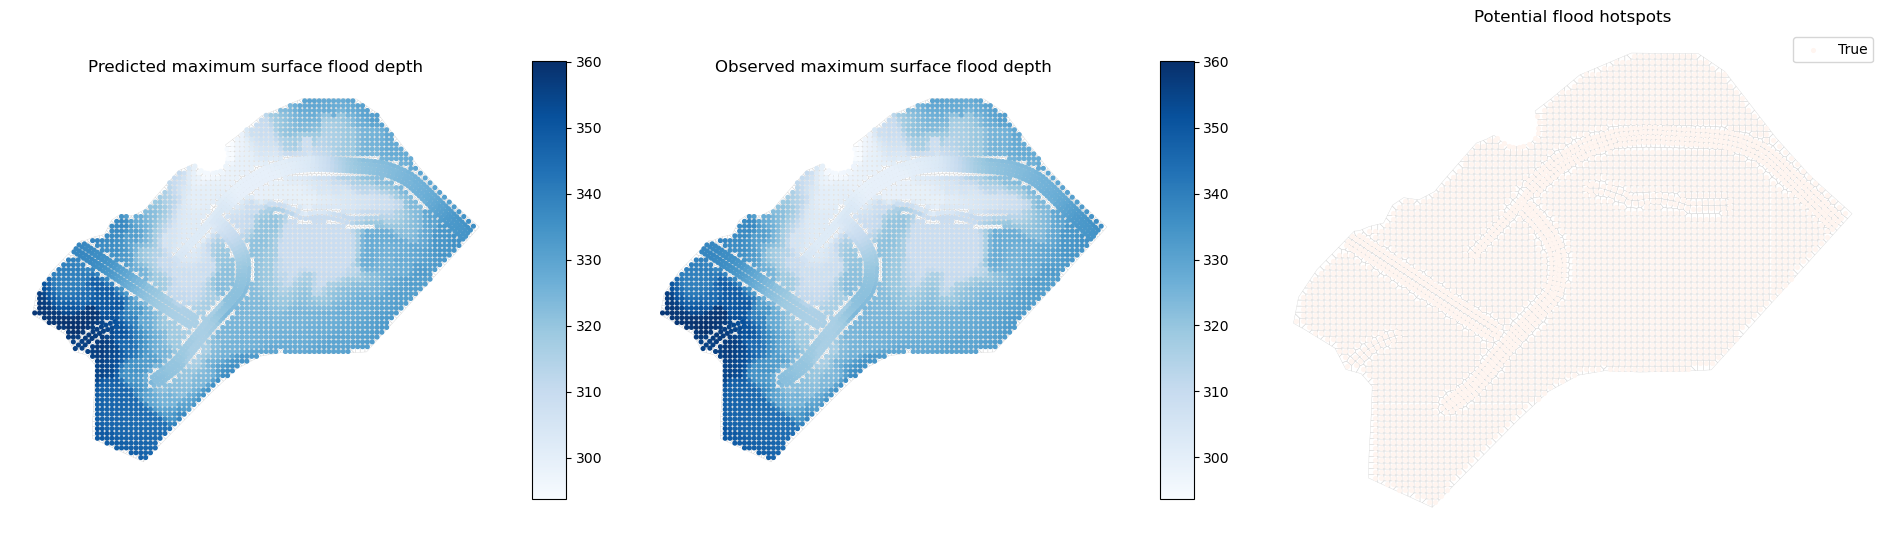

In [47]:
# Create a separate geographical layer for node predictions.

map_gdf = nodes_2d_gdf.copy()

map_gdf["predicted_max_depth_ft"] = (
    maximum_predicted_depth
)

map_gdf["observed_max_depth_ft"] = (
    maximum_observed_depth
)

map_gdf["prediction_error_ft"] = (
    maximum_predicted_depth
    - maximum_observed_depth
)

map_gdf["potential_hotspot"] = (
    maximum_predicted_depth
    >= FLOOD_DEPTH_THRESHOLD_FT
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 7)
)

# Draw the mesh as a geographical background.

mesh_2d_gdf.plot(
    ax=axes[0],
    facecolor="none",
    edgecolor="lightgrey",
    linewidth=0.25
)

map_gdf.plot(
    ax=axes[0],
    column="predicted_max_depth_ft",
    cmap="Blues",
    legend=True,
    markersize=7
)

axes[0].set_title(
    "Predicted maximum surface flood depth"
)

mesh_2d_gdf.plot(
    ax=axes[1],
    facecolor="none",
    edgecolor="lightgrey",
    linewidth=0.25
)

map_gdf.plot(
    ax=axes[1],
    column="observed_max_depth_ft",
    cmap="Blues",
    legend=True,
    markersize=7
)

axes[1].set_title(
    "Observed maximum surface flood depth"
)


mesh_2d_gdf.plot(
    ax=axes[2],
    facecolor="none",
    edgecolor="lightgrey",
    linewidth=0.25
)

map_gdf.plot(
    ax=axes[2],
    column="potential_hotspot",
    cmap="Reds",
    legend=True,
    markersize=7
)

axes[2].set_title(
    "Potential flood hotspots"
)

for ax in axes:

    ax.set_axis_off()
plt.tight_layout()
plt.show()

# Identify the highest-risk locations for further investigation

In [48]:
ranked_hotspots = hotspot_df.sort_values(
    by="maximum_predicted_depth_ft",
    ascending=False
).reset_index(drop=True)


ranked_hotspots["rank"] = (
    np.arange(len(ranked_hotspots)) + 1
)


print("Top 20 predicted surface flood hotspots:")

display(
    ranked_hotspots[
        [
            "rank",
            "node_index",
            "x_coordinate",
            "y_coordinate",
            "maximum_predicted_depth_ft",
            "maximum_observed_depth_ft",
            "prediction_error_ft"
        ]
    ].head(20)
)

Top 20 predicted surface flood hotspots:


,rank,node_index,x_coordinate,y_coordinate,maximum_predicted_depth_ft,maximum_observed_depth_ft,prediction_error_ft
0,1,2202,801876.5625,349207.4375,360.057098,360.046875,0.010223
1,2,2201,801851.5625,349207.4375,359.949493,359.945068,0.004425
2,3,2144,801851.5625,349232.4375,359.387817,359.377441,0.010376
3,4,2200,801826.5625,349207.4375,359.386261,359.370331,0.015930
4,5,2143,801826.5625,349232.4375,359.340454,359.334595,0.005859
5,6,2145,801876.5625,349232.4375,359.314453,359.306152,0.008301
6,7,2257,801876.5625,349182.4375,359.289185,359.269928,0.019257
7,8,2256,801851.5625,349182.4375,359.273590,359.254089,0.019501
8,9,2142,801801.5625,349232.4375,359.187103,359.176605,0.010498
9,10,2203,801901.5625,349207.4375,359.065948,359.052551,0.013397


# Plot the distribution of predicted flood depths

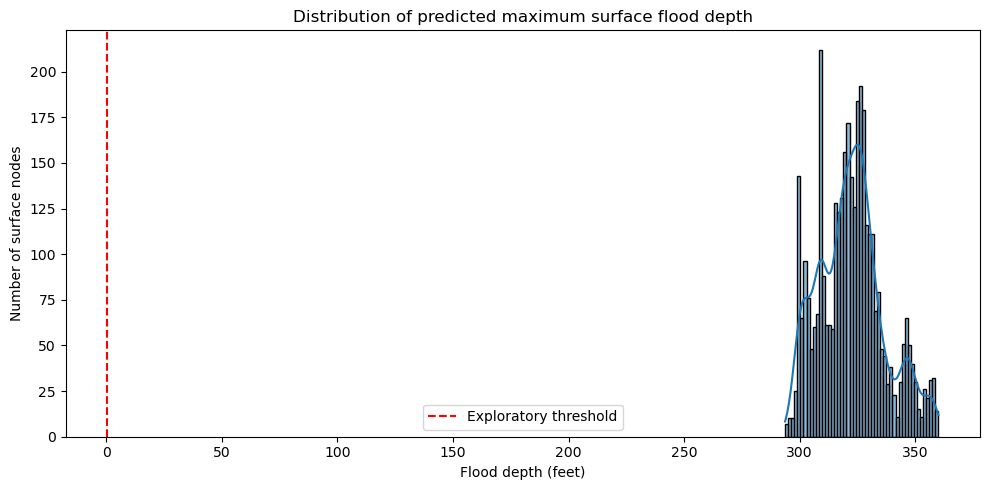

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(
    maximum_predicted_depth,
    bins=50,
    kde=True
)

plt.axvline(
    FLOOD_DEPTH_THRESHOLD_FT,
    linestyle="--",
    color="red",
    label="Exploratory threshold"
)

plt.title(
    "Distribution of predicted maximum surface flood depth"
)

plt.xlabel("Flood depth (feet)")
plt.ylabel("Number of surface nodes")
plt.legend()
plt.tight_layout()
plt.show()

# Calculate flood threshold exceedance performance

Flood threshold classification results:


,Precision,Recall,F1_Score
0,1.0,1.0,1.0


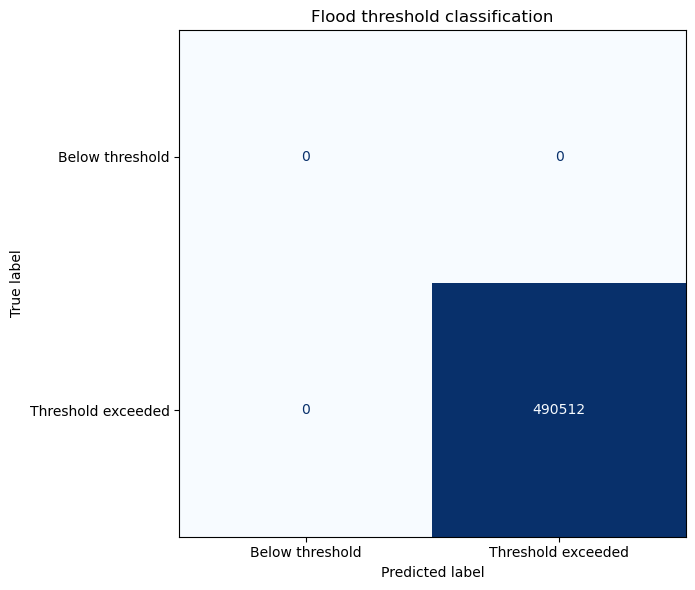


Actual class distribution:
Threshold exceeded    490512
Name: count, dtype: int64

Predicted class distribution:
Threshold exceeded    490512
Name: count, dtype: int64


In [51]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Define the actual and predicted flood conditions

true_binary = (
    observed_depth.ravel()
    >= FLOOD_DEPTH_THRESHOLD_FT
).astype(int)

pred_binary = (
    predicted_depth.ravel()
    >= FLOOD_DEPTH_THRESHOLD_FT
).astype(int)


# Calculate classification metrics

threshold_results = {

    "Precision": precision_score(
        true_binary,
        pred_binary,
        zero_division=0
    ),

    "Recall": recall_score(
        true_binary,
        pred_binary,
        zero_division=0
    ),

    "F1_Score": f1_score(
        true_binary,
        pred_binary,
        zero_division=0
    )

}


print("Flood threshold classification results:")

display(
    pd.DataFrame(
        [threshold_results]
    ).round(5)
)

# Always specify both classes to ensure a 2 x 2 matrix

cm = confusion_matrix(
    true_binary,
    pred_binary,
    labels=[0, 1]
)


# Display the confusion matrix

display_object = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Below threshold",
        "Threshold exceeded"
    ]
)
fig, ax = plt.subplots(figsize=(7, 6))

display_object.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)
plt.title("Flood threshold classification")
plt.tight_layout()
plt.show()
# Inspect class distribution
print("\nActual class distribution:")
print(
    pd.Series(true_binary)
    .value_counts()
    .rename({
        0: "Below threshold",
        1: "Threshold exceeded"
    })
)
print("\nPredicted class distribution:")
print(
    pd.Series(pred_binary)
    .value_counts()
    .rename({
        0: "Below threshold",
        1: "Threshold exceeded"
    })
)

# Evaluate performance for each independent rainfall event

In [52]:
event_ids = [
    sample["event_id"]
    for sample in evaluation_samples
]


unique_events = sorted(
    set(event_ids)
)


event_results = []


for event_id in unique_events:

    indices = np.array([
        i for i, value in enumerate(event_ids)
        if value == event_id
    ])


    for model_name in [
        "Conventional GNN",
        "Physics-Informed GNN"
    ]:

        output = model_predictions[
            model_name
        ]


        for group_name, node_indices in {

            "1D": np.arange(N1),

            "2D": np.arange(N1, N_TOTAL)

        }.items():

            metrics = calculate_metrics(

                output["actual_level"][
                    np.ix_(indices, node_indices)
                ].ravel(),

                output["predicted_level"][
                    np.ix_(indices, node_indices)
                ].ravel()

            )


            event_results.append({

                "Event": event_id,

                "Model": model_name,

                "Node_Type": group_name,

                **metrics

            })


event_results_df = pd.DataFrame(
    event_results
)

display(
    event_results_df.round(5)
)

,Event,Model,Node_Type,RMSE_ft,MAE_ft,R2,NSE,Observations
0,event_11,Conventional GNN,1D,0.01559,0.01143,1.00000,1.00000,204
1,event_11,Conventional GNN,2D,0.00465,0.00285,1.00000,1.00000,44592
2,event_11,Physics-Informed GNN,1D,0.01284,0.00680,1.00000,1.00000,204
3,event_11,Physics-Informed GNN,2D,0.00441,0.00229,1.00000,1.00000,44592
4,event_15,Conventional GNN,1D,0.02458,0.01748,1.00000,1.00000,204
5,event_15,Conventional GNN,2D,0.01175,0.00712,1.00000,1.00000,44592
6,event_15,Physics-Informed GNN,1D,0.02518,0.01609,1.00000,1.00000,204
7,event_15,Physics-Informed GNN,2D,0.01187,0.00707,1.00000,1.00000,44592
8,event_16,Conventional GNN,1D,0.02944,0.01946,1.00000,1.00000,204
9,event_16,Conventional GNN,2D,0.00660,0.00376,1.00000,1.00000,44592


# Compare performance across rainfall events

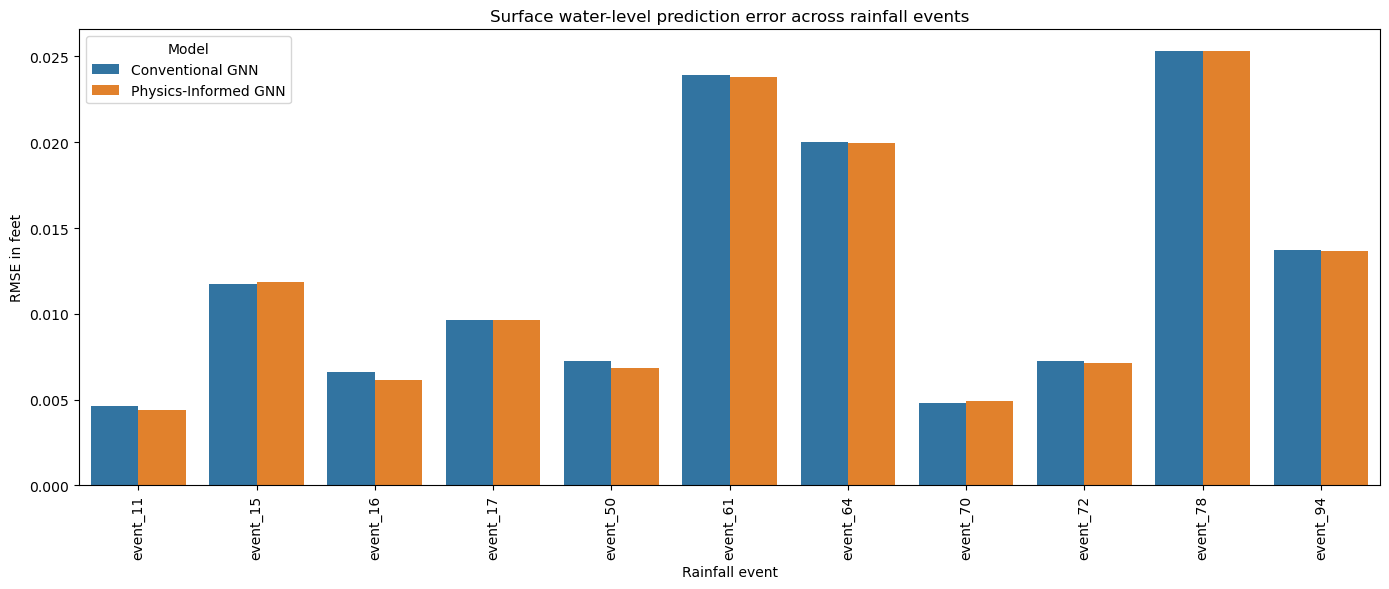

In [53]:
event_2d_results = event_results_df[
    event_results_df["Node_Type"] == "2D"
].copy()


plt.figure(figsize=(14, 6))

sns.barplot(
    data=event_2d_results,
    x="Event",
    y="RMSE_ft",
    hue="Model"
)

plt.title(
    "Surface water-level prediction error across rainfall events"
)

plt.xlabel("Rainfall event")
plt.ylabel("RMSE in feet")
plt.xticks(rotation=90)
plt.legend(
    title="Model"
)
plt.tight_layout()
plt.show()

# Investigate the effect of different flood thresholds

In [54]:
thresholds = [
    0.25,
    0.50,
    1.00,
    1.50
]


threshold_sensitivity = []


for threshold in thresholds:

    actual_binary = (
        observed_depth.ravel() >= threshold
    ).astype(int)

    predicted_binary = (
        predicted_depth.ravel() >= threshold
    ).astype(int)


    threshold_sensitivity.append({

        "Threshold_ft": threshold,

        "Precision": precision_score(
            actual_binary,
            predicted_binary,
            zero_division=0
        ),

        "Recall": recall_score(
            actual_binary,
            predicted_binary,
            zero_division=0
        ),

        "F1_Score": f1_score(
            actual_binary,
            predicted_binary,
            zero_division=0
        )

    })


threshold_sensitivity_df = pd.DataFrame(
    threshold_sensitivity
)

display(
    threshold_sensitivity_df.round(5)
)

,Threshold_ft,Precision,Recall,F1_Score
0,0.25,1.0,1.0,1.0
1,0.50,1.0,1.0,1.0
2,1.00,1.0,1.0,1.0
3,1.50,1.0,1.0,1.0


# Estimate uncertainty in event-level performance

In [55]:
def bootstrap_event_rmse(
    event_results,
    model_name,
    repetitions=2000
):

    selected = event_results[
        (event_results["Model"] == model_name)
        & (event_results["Node_Type"] == "2D")
    ]


    values = selected.groupby(
        "Event"
    )["RMSE_ft"].mean().to_numpy()


    rng = np.random.default_rng(SEED)

    bootstrap_means = []


    for _ in range(repetitions):

        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )

        bootstrap_means.append(
            np.mean(sample)
        )


    return {

        "Model": model_name,

        "Mean_RMSE": np.mean(values),

        "Lower_95_CI": np.percentile(
            bootstrap_means,
            2.5
        ),

        "Upper_95_CI": np.percentile(
            bootstrap_means,
            97.5
        )

    }


confidence_results = pd.DataFrame([

    bootstrap_event_rmse(
        event_results_df,
        "Conventional GNN"
    ),

    bootstrap_event_rmse(
        event_results_df,
        "Physics-Informed GNN"
    )

])


display(
    confidence_results.round(5)
)

,Model,Mean_RMSE,Lower_95_CI,Upper_95_CI
0,Conventional GNN,0.01226,0.00820,0.01634
1,Physics-Informed GNN,0.01216,0.00805,0.01628
